# ADEPT Sensitivity Analysis: Federated Learning System

This notebook applies the ADEPT pipeline to a federated learning (FL) system that composes three architectural patterns: a **client selector**, a **message compressor** and **heterogeneous data handling** (HDH). The steps are:

1. load the system definition and the runs, and summarize the design space;
2. check the spec against the data (linter);
3. define tradeoffs over **model accuracy** and **total round time**;
4. split the runs into train and test sets;
5. relate configurations (composite decisions) and each pattern's policies (marginal decisions) to the tradeoffs (contingency), and compare each pattern ON and OFF under matched conditions (matched contrasts);
6. measure how robustly each configuration reaches each tradeoff;
7. relate the amount of patterning in a run (pattern stress) to the tradeoffs;
8. rank the parameters that explain the objectives;
9. and 10. describe tradeoff regions as boxes over those parameters (PRIM, CART);
11. to 13. estimate what the boxes would improve, inspect them, and score the discovery algorithms.

The runs analyzed are chosen in the parameters cell below (`SLICE`, `CLIENTS`, `TASK`, `ENVIRONMENT`). The text explains what each step computes and how to read it; it does not describe the results of any particular run, so it stays valid when the parameters or the data change. The results are the cell outputs. The data and the notebook families are described in `compact/README.md`.

> **Pattern-stress analysis: 4 clients, text classification (AG_NEWS + MLP).**
>
> Generated from `analysis-fl.ipynb` by `make_slice_notebooks.py`; edit the base notebook and regenerate instead of editing this one.
> All configurations are loaded from `./compact/FLsystem_compact_all.json` (both CSVs), restricted to 4 clients, this task, and only the environment points at which **every** configuration was run (`ENVIRONMENT = 'common'`), so configurations and stress levels are compared under identical conditions. Section 7 compares the pattern-stress levels; its assumptions on pattern instances are listed in `compact/README.md`.
> Tradeoff edges are **detected on this notebook's runs**: regions are comparable inside the notebook, not with other client counts or tasks.


In [1]:
# Set project root in path so we can import 'adept' package
import sys
sys.path.append("..")

import contextlib
import io
import itertools
import json
import pandas as pd
import matplotlib.pyplot as plt

from adept import PatternAnalysis
from adept.utils.linter import SystemLinter
from adept.utils.spec_summary import summarize_system

import fl_slices

# The spec declares how the per-client columns ("Client <N> <field>") are aggregated
# into system-level parameters and objectives (dataspace.aggregations, see
# adept/utils/aggregation.py); fl_slices.slice_filter only adds the pattern-stress
# columns and filters the runs.

In [2]:
# ---- Analysis parameters
# Which runs to analyze (see fl_slices.py). Focused notebooks are generated from this one
# by make_slice_notebooks.py, which only changes this cell.
#   'all'                -> every run (this notebook)
#   'baseline'           -> All Patterns Off
#   'client_selector', 'message_compressor', 'hdh' -> that pattern alone ON
SLICE = 'all'
# For a single-pattern slice, also keep the baseline runs (pattern ON vs. not applied)
INCLUDE_BASELINE = False
# Further filters (None = keep all):
#   CLIENTS     -> number of clients (`Total Clients`), e.g. 4, 8, 10
#   TASK        -> 'image' (CIFAR-10 + CNN 16k) or 'text' (AG_NEWS + MLP)
#   ENVIRONMENT -> 'all', or 'common': only the environment points (low-spec, non-IID and
#                  delay shares) at which every configuration was run
CLIENTS = 4
TASK = 'text'
ENVIRONMENT = 'common'
# All 8 configurations from both compact CSVs (see compact/README.md)
SPEC = './compact/FLsystem_compact_all.json'

# Tradeoffs (Section 3): the bins of each objective, and their edges.
#   TRADEOFF_EDGES = None -> edges detected from the loaded data (equal-width bins over its
#                            range, padded by 0.1)
#   {objective: [e0, ..., en]} -> fixed edges for the n labels of that objective. The
#                            focused notebooks get the edges detected on the full dataset
#                            (make_slice_notebooks.py), so they share this notebook's regions.
TRADEOFF_LABELS = {
    'final_val_accuracy': ['S', 'M', 'L'],
    'avg_total_time': ['S', 'M', 'L'],
}
TRADEOFF_EDGES = None


## 1. Load System & Model Summary

We create a `PatternAnalysis` session from the system definition (`SPEC`) and load its runs through `fl_slices.slice_filter`, which adds the pattern-stress columns and keeps only the runs selected in the parameters cell. The spec declares how per-client columns are aggregated into run-level parameters and objectives (`dataspace.aggregations`).

The model summary (`summarize_system`) lists the system's decisions, policies, parameter bindings and configuration coverage, so they can be checked before any analysis builds on them.

In [3]:
session = PatternAnalysis(SPEC)
session.load(preprocessor=fl_slices.slice_filter(
    SLICE, INCLUDE_BASELINE, clients=CLIENTS, task=TASK, environment=ENVIRONMENT
))

print(f"Loaded {len(session.raw_df)} experiments.")
print()
print(summarize_system(session.sys_def))

Using CSV delimiter: ','
Loading source file: ./compact/adept_experiments_all_waves.csv
Loaded 1380 rows.
Loading source file: ./compact/adept_experiments_all_waves_combinedAP.csv
Loaded 960 rows.
Concatenated 2 files: 2340 rows.
Applying preprocessor hook to source data...


HDH instances: measured from the per-round data for 2340 of 2340 runs (HDH Time > 0); rule A3 for the others.
Slice: kept 80 of 2340 runs (4 clients; task 'text' (AG_NEWS + MLP); common environment points).
[WARNING] Dataspace.QualityObjectives: Quality Objective 'RAM Usage Avg Mean' is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
[WARNING] System.Components: Parameter 'N Rounds' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
[WARNING] System.Components: Parameter 'Total Clients' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
[WARNING] System.Components: Parameter 'Model' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
[WARNING] System.Components: Parameter 'Dataset' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshol

### The design space

`fl_system` is a single component that composes **three independent ON/OFF pattern decisions**:

| Decision | `OFF` | `ON` | Parameters bound by `ON` |
|:---|:---|:---|:---|
| `client_selector_pattern` | every client trains | only clients that meet a resource criterion train | `Client Selector Strategy`, `Criteria`, `Value` |
| `message_compressor_pattern` | messages are sent uncompressed | client messages are compressed | `Message Compressor Alg` |
| `hdh_pattern` | no data augmentation | clients augment their data with a generative model | the `HDH ...` settings |

Besides these pattern parameters (constraints), the spec declares:

- **levers**: system settings the architect controls, such as the model, dataset, number of clients and rounds, and the number of active pattern types;
- **uncertainties**: conditions the architect does not control, such as the shares of low-spec, non-IID and delayed clients, client resources, data heterogeneity, and the number of deployed pattern instances;
- **quality objectives**: model quality (F1 and accuracy, maximize) and cost (training, communication and total round time, CPU and RAM usage, minimize).

### Reading the model summary

- **Configurations.** A configuration fixes one policy per decision, written `client_selector,message_compressor,hdh` (for example `OFF,OFF,OFF` is the baseline). The analysis describes configurations present in the loaded runs; variation by pattern composition can be examined only where combinations were run.
- **Runs per configuration.** When the counts differ, results pooled over configurations (per decision, or per stress level) weight the configurations unequally.
- **Parameters that vary.** Only parameters with more than one value in the loaded runs can explain differences between runs. Each filter in the parameters cell (`CLIENTS`, `TASK`, ...) turns the factor it fixes into a constant.
- **Pattern parameters** have a single value when their pattern is ON and are empty when it is OFF, so each one records *whether* its pattern is on rather than a tunable value.

The analysis targets **model accuracy × total round time** (`final_val_accuracy` × `avg_total_time`), the classic FL tradeoff (Section 3).

## 2. Linter Sanity Check

`SystemLinter` checks the spec against the loaded data. It runs on `session.raw_df` (parameters and objectives) rather than `session.experiments_df` (parameters only), which lacks the objective columns and would report every objective as missing; `session.load()` lints the same combined frame.

The notebook stops if the linter reports an `ERROR`. `WARNING`s do not stop it; the next cell explains how to read them.

In [4]:
issues = SystemLinter().lint(session.sys_def, session.raw_df)
errors = [i for i in issues if i.level == "ERROR"]
warnings_ = [i for i in issues if i.level == "WARNING"]

print(f"Linter findings: {len(errors)} ERROR(s), {len(warnings_)} WARNING(s)")
for issue in issues:
    print(" ", issue)

assert not errors, f"Linter reported ERROR-level issues; fix the spec before proceeding: {errors}"

Linter findings: 0 ERROR(s), 17 WARNING(s)
  [WARNING] Dataspace.QualityObjectives: Quality Objective 'RAM Usage Avg Mean' is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
  [WARNING] System.Components: Parameter 'N Rounds' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
  [WARNING] System.Components: Parameter 'Total Clients' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
  [WARNING] System.Components: Parameter 'Model' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
  [WARNING] System.Components: Parameter 'Dataset' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (threshold 70%).
  [WARNING] System.Components: Parameter 'Optimizer' (Component: fl_system) is low-variance: 100.0% of values are concentrated on a single value (

### Reading the linter warnings

| Warning | What it means for the analysis |
|:---|:---|
| **Policy-combination coverage** | Some configurations are not in the loaded runs. Conclusions apply only to the configurations present. Expected for slices that keep only some configurations. |
| **Low variance near 100%** | The parameter has (almost) one value in these runs, so it cannot explain differences between runs, and feature scoring (Section 8) gives it (near) zero importance. Expected for factors fixed by the experiment design or by the slice. |
| **Low variance on pattern parameters** | Their most frequent value is "not selected": they are empty whenever their pattern is OFF. They carry "pattern on or off", not a tunable value. |
| **Low variance on an objective** | Most runs share one value, so the objective separates runs poorly as a tradeoff axis. |
| **Missing values (NaN semantics)** | A parameter has missing values but is not declared `optional`, or an objective has missing values (see `docs/nan_strategy.md`). Resolve these in the spec or the data before reading the results. |

> Warnings explained by the experiment design or the slice are expected. Any other warning points to a spec or data issue.

In [5]:
print(f"Loaded {len(session.raw_df)} experiments.")
session.raw_df.head()

Loaded 80 experiments.


,N Rounds,Total Clients,Model,Dataset,Optimizer,Learning Rate,Batch Size,Epochs,Client 1 ID,Client 1 CPU,...,HDH Instances,Pattern Instances,CPU Mean,RAM Mean,Data Distribution Diversity,Data Persistence Diversity,Alpha Dirichlet Mean,JSD Mean,CPU Usage Avg Mean,RAM Usage Avg Mean
0,20,4,MLP,AG_NEWS,Adam,0.001,64,1,Client 1,12,...,0,0,10.75,4.0,2,1,0.875,NaN,861.775000,0.0
1,20,4,MLP,AG_NEWS,Adam,0.001,64,1,Client 1,12,...,0,1,10.75,4.0,2,1,0.875,NaN,898.516667,0.0
2,20,4,MLP,AG_NEWS,Adam,0.001,64,1,Client 1,12,...,1,1,10.75,4.0,2,1,0.875,0.0,857.787500,0.0
3,20,4,MLP,AG_NEWS,Adam,0.001,64,1,Client 1,12,...,0,4,10.75,4.0,2,1,0.875,NaN,828.687500,0.0
4,20,4,MLP,AG_NEWS,Adam,0.001,64,1,Client 1,12,...,0,0,10.75,4.0,2,1,0.875,NaN,944.937500,0.0


## 3. Define Tradeoffs

The spec declares several quality objectives. Discretizing all of them combinatorially would create far more regions than there are runs, and most would be empty. We discretize the **classic FL tradeoff**, with the bins given in `TRADEOFF_LABELS`:

- **model accuracy**: `final_val_accuracy`, the accuracy of the global model after the last round (maximize);
- **total round time**: `avg_total_time`, the average wall-clock time of a round, training plus communication (minimize).

The F1 objectives stay in the spec and can replace accuracy as a robustness check.

Bin edges come from the parameters cell. With `TRADEOFF_EDGES = None` they are detected from the loaded runs (equal-width bins over the observed range, padded by 0.1). With explicit edges, every notebook that uses them shares the same regions, so their results can be compared.

In [6]:
# ---- Discretization of the objectives (labels and edges: see the parameters cell)
tradeoffs, schemes = session.create_tradeoffs(
    method='discretization', labels=TRADEOFF_LABELS, edges=TRADEOFF_EDGES
)

print(len(tradeoffs), "possible tradeoffs (regions)")
for scheme in schemes:
    print(f"Objective: {scheme.objective_name}")
    print("  edges:", [scheme.bins[0].min_value] + [b.max_value for b in scheme.bins])
    for b in scheme.bins:
        print(f"  {b.label}: [{b.min_value:.2f}, {b.max_value:.2f}]")


Creating discretization tradeoffs with 3 bins.
9 possible tradeoffs (regions)
Objective: final_val_accuracy
  edges: [0.8009000000000001, 0.872, 0.9431, 1.0142]
  S: [0.80, 0.87]
  M: [0.87, 0.94]
  L: [0.94, 1.01]
Objective: avg_total_time
  edges: [4.164500000000001, 7.456, 10.747499999999999, 14.038999999999998]
  S: [4.16, 7.46]
  M: [7.46, 10.75]
  L: [10.75, 14.04]


### Reading the tradeoffs

- **Names.** A tradeoff (region) is named `<accuracy bin>-<time bin>`. `L-S` (high accuracy, fast) is the ideal region and `S-L` (low accuracy, slow) the worst.
- **Edges.** The cell prints the edges of each objective. Check whether they were detected on these runs or fixed (parameters cell): detected edges make regions comparable only within this notebook.
- **Populated regions.** The split (Section 4) and the objective-space plot show how many runs each region holds. Regions with few runs yield boxes that are hard to validate; empty regions get no box.
- **Effects of the factors.** To see how a pattern moves the objectives, compare mean accuracy and round time per configuration under the same task and client count (Section 7 gives these tables). Pooling over tasks or client counts lets those factors dominate the comparison.

## 4. Data Splitting

We split the runs into train and test sets, stratified by tradeoff region: feature scoring (Section 8) and box discovery use the training runs, and boxes and robustness are evaluated on the test runs (Sections 9-11).

In [7]:
session.split_data(test_size=0.3, remove_outliers=False, verbose=True)

Data split: 56 train, 24 test.

--- Train Set Tradeoff Counts ---
  M,S: 8 (14.29%)
  M,L: 48 (85.71%)

--- Test Set Tradeoff Counts ---
  M,S: 4 (16.67%)
  M,L: 20 (83.33%)


### Reading the split

- **Stratification.** Each region should have the same share of runs in train and test. A region with a single run cannot be stratified; the split then falls back to a seeded (reproducible) random split, and says so above.
- **Regions without test runs.** Boxes found for them cannot be validated.
- **Small test groups.** Test-set robustness moves in steps of 1/n for a group with n test runs (with 2 runs, the only possible success rates are 0, 0.5 and 1). Read densities and success rates together with these counts.

The histograms show the distribution of each objective over the loaded runs.

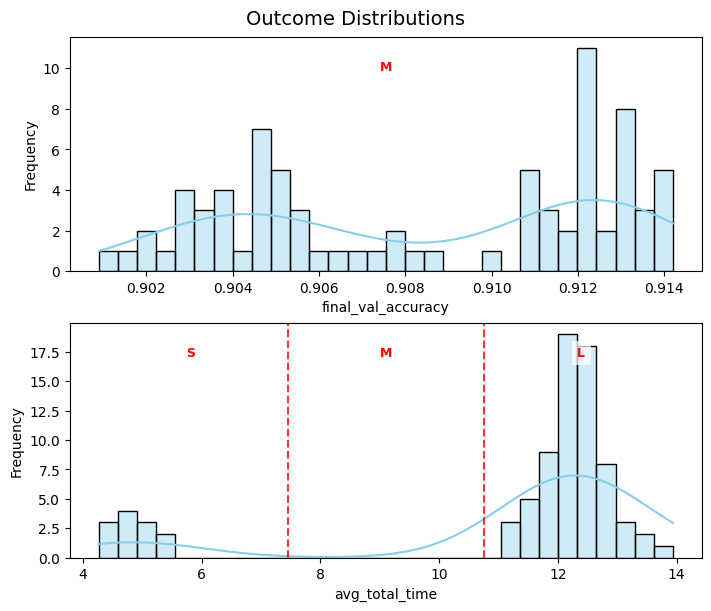

In [8]:
session.show_distributions(figsize=(7,3))
plt.show()

### How to read `S`, `M` and `L`

- **`S`, `M`, `L` = small, medium, large value**, not good or bad. Whether a value is good depends on the objective's direction: for `final_val_accuracy` (maximize) `L` is best; for `avg_total_time` (minimize) `S` is best.
- **Labels are relative**, to the loaded runs (detected edges) or to the dataset the fixed edges were detected on. An `L` accuracy means "among the highest in these runs", not a good accuracy in absolute terms.
- **Padding.** Detected edges pad the observed range by 0.1 in objective units. That is negligible for time (seconds) but large for accuracy (between 0 and 1), so the outer accuracy bins can be partly empty.
- **Clusters.** A histogram with several modes usually reflects a factor that shifts the objective, such as the task or the number of clients. When an edge cuts through a cluster, small differences between replications can change a run's bin. Read "a pattern moves runs up a bin" with care, and check whether runs of one configuration land in several regions.

> **Tip.** To cut an objective at meaningful limits instead of equal widths, set `TRADEOFF_EDGES` in the parameters cell, or use `create_tradeoffs(method='threshold', thresholds={...})`.

We map the runs onto the objective space, with the bin edges drawn as a grid, to see the shape and density of the tradeoff regions.

In [9]:
tradeoff_labels = [t.name for t in tradeoffs]
tradeoff_labels

['S-S', 'S-M', 'S-L', 'M-S', 'M-M', 'M-L', 'L-S', 'L-M', 'L-L']

In [10]:
session.get_decisions()

{'client_selector_pattern': Decision(description='Pattern for selecting which clients participate in training', policies={'OFF': PatternPolicy(description='Client selector pattern disabled - all clients participate', parameter_bindings=ParameterBindings(levers={}, uncertainties={}, constraints={})), 'ON': PatternPolicy(description='Client selector pattern enabled - Resource-Based selection', parameter_bindings=ParameterBindings(levers={}, uncertainties={}, constraints={'Client Selector Strategy': 'Resource-Based', 'Client Selector Criteria': 'CPU', 'Client Selector Value': 2.0}))}),
 'message_compressor_pattern': Decision(description='Pattern for compressing messages exchanged between clients and server', policies={'OFF': PatternPolicy(description='Message compressor disabled', parameter_bindings=ParameterBindings(levers={}, uncertainties={}, constraints={})), 'ON': PatternPolicy(description='Message compressor enabled - zlib compression', parameter_bindings=ParameterBindings(levers={}

In [11]:
session.get_policies()

{'OFF,OFF,OFF': SystemConfiguration(name='Baseline (all patterns off)', description='No architectural patterns enabled.', pattern_policy_references=[PatternPolicyReference(component='fl_system', decision='client_selector_pattern', policy='OFF'), PatternPolicyReference(component='fl_system', decision='message_compressor_pattern', policy='OFF'), PatternPolicyReference(component='fl_system', decision='hdh_pattern', policy='OFF')], source_file=None, component_policies={}),
 'ON,OFF,OFF': SystemConfiguration(name='Client selector only', description='Resource-based client selection enabled.', pattern_policy_references=[PatternPolicyReference(component='fl_system', decision='client_selector_pattern', policy='ON'), PatternPolicyReference(component='fl_system', decision='message_compressor_pattern', policy='OFF'), PatternPolicyReference(component='fl_system', decision='hdh_pattern', policy='OFF')], source_file=None, component_policies={}),
 'OFF,ON,OFF': SystemConfiguration(name='Message compre

### Decisions, policies and configurations

The two cells above list the same design space at two levels:

| Term | What it is | In this system | Where to see it |
|:---|:---|:---|:---|
| **Decision** | a design choice point for one pattern | `client_selector_pattern`, `message_compressor_pattern`, `hdh_pattern` | `get_decisions()` |
| **Policy** | one option of a decision; it binds values to constraint parameters | `ON` or `OFF` for each decision | `get_decisions()[d].policies` |
| **Configuration** | one policy per decision, i.e. a full system variant | e.g. `OFF,OFF,OFF` (baseline), `ON,OFF,ON` | `get_policies()`, column `config_id` |

Note that `get_policies()` returns **configurations** (ADEPT calls them system-level policies). Robustness results (Sections 6 and 11) are reported per configuration by default; pass `by='decision'` to report per decision policy instead (e.g. `hdh_pattern:ON`), or `by=<column>` to group by a run attribute (Section 7 groups by pattern stress).

#### What else the model contains

| Element | Role | Examples |
|:---|:---|:---|
| **Levers** | design settings controlled by the architect | `Model`, `Total Clients`, rounds, learning rate |
| **Constraints** | the settings a pattern's `ON` policy fixes; empty when the pattern is OFF, which ADEPT encodes as a separate "not selected" value | `Client Selector Value`, `HDH Latent Dim` |
| **Uncertainties** | conditions the architect does not control | shares of low-spec, non-IID and delayed clients; client CPU/RAM; data heterogeneity |
| **Quality objectives** | measured outcomes of each run | `final_val_accuracy` and `avg_total_time` are analyzed; the others stay in the spec |

All three parameter kinds are candidate *explanations* of the objectives: Section 8 scores how much each one matters, and Sections 9-10 describe tradeoff regions as ranges over the top-ranked ones.

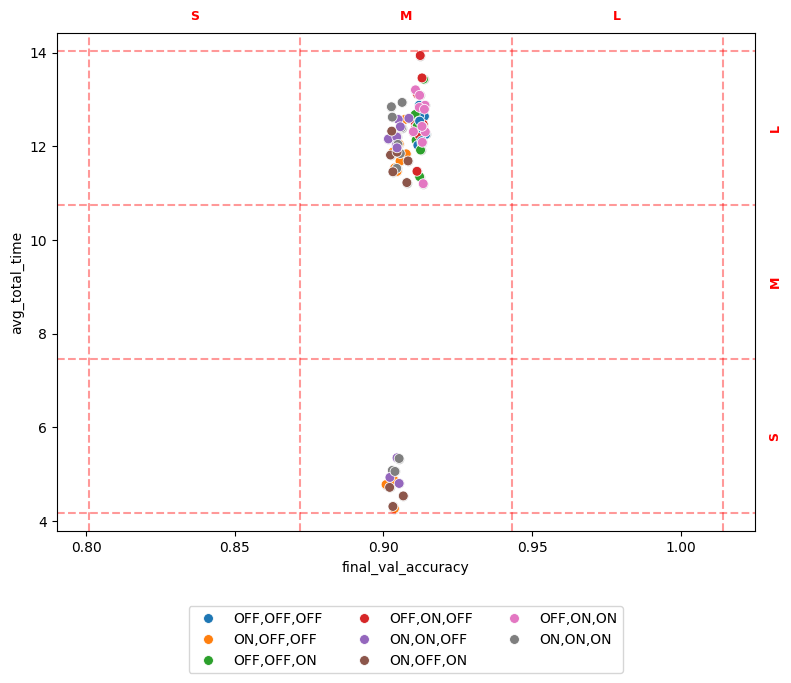

In [12]:
outcome_cols = list(session.outcomes_df.columns)
# Plot the policies for all combinations (pairs) of quality objectives
for x_col, y_col in itertools.combinations(outcome_cols, 2):
    fig = session.show_quality_objective_space(
        x_col, y_col,
        highlight_policies=session.get_policies(), 
        # highlight_tradeoffs=[session.get_tradeoff(tradeoffs[7].name)],
        # show_overall=True,
        subset='all',
        cmap='tab10', 
        alpha=1.0,
        figsize=(8, 7),
        s=50,
        title=""
    )
    # fig.savefig(f'fl-quality_objective_space_{x_col}_{y_col}.png', dpi=500)
    plt.show()

### Reading the objective space

- **Points and colors.** Each point is one run, colored by its configuration.
- **Grid.** The dashed lines are the bin edges, so each grid cell is one tradeoff region: columns are the accuracy bin (`S`, `M`, `L` from left to right), rows the time bin (`S`, `M`, `L` from bottom to top). The ideal region `L-S` is the bottom-right cell.
- **What to look for:**
  - clusters of runs, which usually correspond to a factor such as the task or the number of clients;
  - whether the runs of one configuration stay in one region or straddle an edge;
  - which configurations reach the high-accuracy column, and at what time cost.

## 5. Contingency Analysis: Composite and Marginal Decisions

Contingency counts how the runs of each policy group spread over the tradeoff regions. In a multi-pattern system, "policy" can mean two things, selected with the `by` argument:

- **Composite decisions** (`by='configuration'`, the default): one row per configuration, i.e. per combination of the three pattern policies (`OFF,ON,ON`, ...). This is what an architect actually deploys, and it is the faithful view of a multi-pattern system.
- **Marginal decisions** (`by='<decision>'` or `by='decision'` for all of them): one row per policy of one pattern. A marginal row pools every configuration with that policy, weighted by its runs, so it describes the pattern *on average over the other decisions as they were sampled*.

From each table we list:

- **deterministic groups**: groups whose runs all fall in a single region;
- **exclusive tradeoffs**: regions reached by only one group of the grouping (for `by='decision'`, within each decision).

Marginal results mix configurations and conditions, so the section ends with **matched contrasts**, which compare a pattern ON and OFF under the same conditions.

Only decisions with more than one policy in the loaded runs are analyzed marginally. When no decision varies (a slice with a single configuration), the spread of the runs comes from the context, so the runs are grouped by the context factors that vary instead: client count, model (task) and environment.

In [13]:
# Groupings for the contingency analysis: composite decisions (configurations) first,
# then the marginal view of each decision that varies in these runs. Without varying
# decisions, group by the context factors that vary instead.
varying_decisions = session.get_varying_decisions()
CONTEXT_COLUMNS = ['Total Clients', 'Model', *fl_slices.ENVIRONMENT_COLUMNS]
context_groupings = [c for c in CONTEXT_COLUMNS
                     if c in session.experiments_df.columns and session.experiments_df[c].nunique() > 1]

contingency_groupings = ['configuration'] + (varying_decisions or context_groupings)
print("Decisions that vary in these runs:", varying_decisions or "none")
if not varying_decisions:
    print("Context factors that vary:", context_groupings or "none")
print("Contingency groupings:", contingency_groupings)

Decisions that vary in these runs: ['client_selector_pattern', 'message_compressor_pattern', 'hdh_pattern']
Contingency groupings: ['configuration', 'client_selector_pattern', 'message_compressor_pattern', 'hdh_pattern']


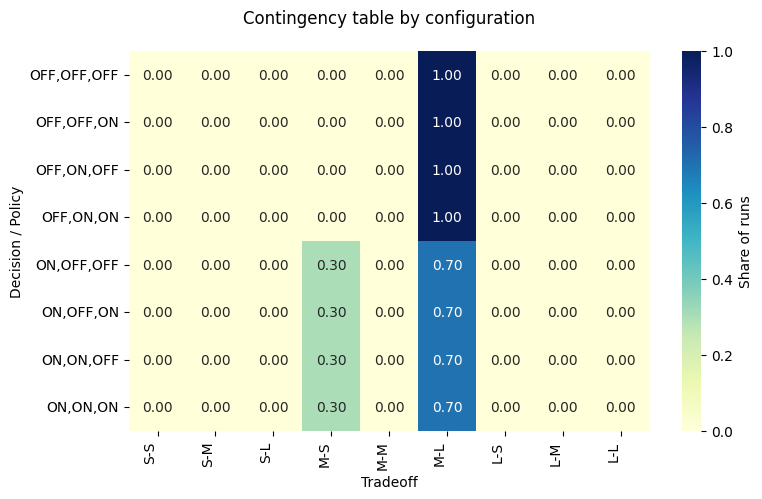

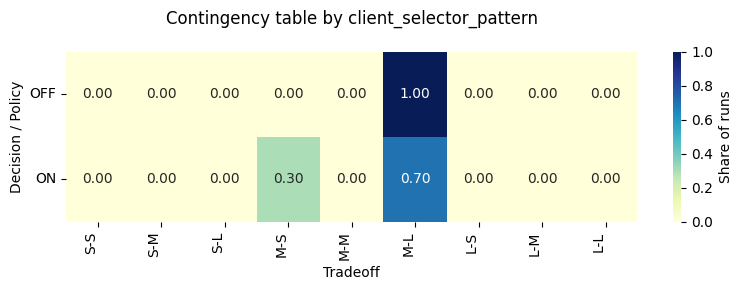

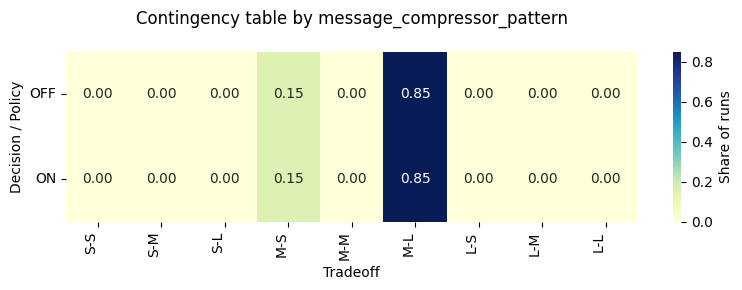

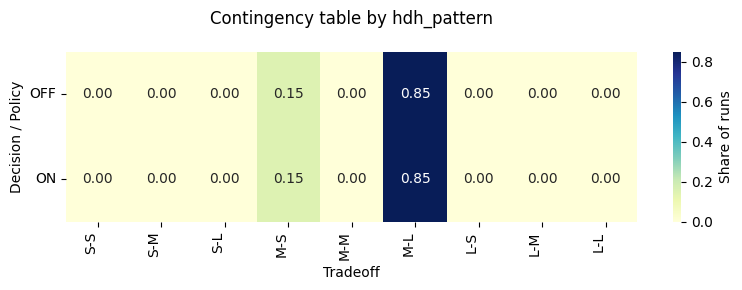

In [14]:
for by in contingency_groupings:
    n_rows = len(session.get_policy_contingency_matrix(by=by))
    session.show_policy_contingency(
        by=by,
        type='heatmap',
        subset='all',
        title=f"Contingency table by {by}",
        figsize=(8, max(3, 0.45 * n_rows + 1.5))
    )
    plt.show()

In [15]:
print("Deterministic groups (all their runs fall in a single tradeoff)")
for by in contingency_groupings:
    print("---" * 10)
    print("Grouping:", by)
    pairs = session.get_deterministic_policies(by=by)
    for policy, tradeoff in pairs:
        print("* Group:", policy, "--> Tradeoff:", tradeoff)
    if not pairs:
        print("  none")

Deterministic groups (all their runs fall in a single tradeoff)
------------------------------
Grouping: configuration
* Group: OFF,OFF,OFF --> Tradeoff: M-L
* Group: OFF,OFF,ON --> Tradeoff: M-L
* Group: OFF,ON,OFF --> Tradeoff: M-L
* Group: OFF,ON,ON --> Tradeoff: M-L
------------------------------
Grouping: client_selector_pattern
* Group: OFF --> Tradeoff: M-L
------------------------------
Grouping: message_compressor_pattern
  none
------------------------------
Grouping: hdh_pattern
  none


In [16]:
print("Exclusive tradeoffs (reached by a single group of the grouping)")
for by in contingency_groupings:
    print("---" * 10)
    print("Grouping:", by)
    pairs = session.get_exclusive_tradeoffs(by=by)
    for policy, tradeoff in pairs:
        print("* Tradeoff:", tradeoff, "--> Group:", policy)
    if not pairs:
        print("  none")

Exclusive tradeoffs (reached by a single group of the grouping)
------------------------------
Grouping: configuration
  none
------------------------------
Grouping: client_selector_pattern
* Tradeoff: M-S --> Group: ON
------------------------------
Grouping: message_compressor_pattern
  none
------------------------------
Grouping: hdh_pattern
  none


### Reading the contingency results

- **Start with the composite view.** A deterministic configuration always leads to one region; an exclusive region is reached by one configuration only.
- **Marginal results are mixtures.** A deterministic marginal policy means that *every* configuration with that policy reaches the same region, a strong claim. The absence of a deterministic marginal policy says nothing about the configurations themselves.
- **Marginal exclusivity is not attribution.** A region reached only by configurations that share two `ON` policies (for example `ON,OFF,ON` and `ON,ON,ON`) is reported as exclusive to *both* policies in the marginal view. Check the composite table to see which combination reaches it. Attributing a region to one pattern requires comparing configurations that differ in that decision only: the matched contrasts below.
- **Unequal weights.** If the configurations of a marginal row have different numbers of runs, the row leans toward the larger ones.
- **Context grouping** (single-configuration slices) shows what drives the spread when no pattern varies: client count, task or environment. It is not a pattern effect.
- **Exclusivity needs at least two groups.** With a single group, every reached region would be trivially exclusive, so ADEPT reports none and prints a warning.

### Matched-condition contrasts by partition seed

Contingency compares groups of runs that may differ in more than the pattern: one configuration can have more text runs, or more runs with many clients, than another. A **matched one-factor contrast** compares a pattern ON with the same configuration with that pattern OFF, within shared task, client-count, environment, and data-partition seed:

1. **Select the configuration pair** that differs only in the pattern. By default (`CONTRAST_OTHERS = 'reference'`) the other patterns are OFF, so each pattern alone is compared with the baseline: `ON,OFF,OFF`, `OFF,ON,OFF` and `OFF,OFF,ON` against `OFF,OFF,OFF`.
2. **Match the runs** on task (`Dataset`), client count, environment, and `partition_seed` (`MATCH_ON`). A seed is included only when both configurations have a run for it.
3. **Compare within each matched unit**: treatment minus reference for each objective, with support counts. With `partition_seed` included, each arm contributes one run to each matched unit.
4. **Summarize with equal weights**: the mean and range of seed-matched differences, and the share of matched units with a positive raw difference.

The result is a seed-matched *descriptive* contrast over observed runs, not a causal estimate. Matching by partition seed does not match host, scheduling, or other unrecorded conditions. A single-configuration slice (e.g. the baseline notebook) has nothing to contrast; this section of the overview notebook covers all three patterns.

In [17]:
# Matched one-factor contrasts: each pattern ON vs. OFF, within settings run under the same conditions
MATCH_ON = [c for c in ['Dataset', 'Total Clients', *fl_slices.ENVIRONMENT_COLUMNS, 'partition_seed'] if c in session.raw_df.columns]
CONTRAST_OTHERS = 'reference'  # 'reference': other patterns OFF (vs. the baseline); 'all': every combination
contrast_objectives = list(TRADEOFF_LABELS)
print("Matched on:", MATCH_ON)

contrast_settings = {}
for decision in varying_decisions:
    settings, summary = session.get_decision_contrasts(
        decision, MATCH_ON, others=CONTRAST_OTHERS, objectives=contrast_objectives)
    if summary.empty:
        continue
    contrast_settings[decision] = settings
    print(f"\n=== {decision}: ON - OFF, {int(summary['settings'].sum())} matched seed-settings ===")
    display(summary.T.round(3))
if not varying_decisions:
    print("No decision varies in these runs: no contrast. The overview notebook contrasts every pattern with the baseline.")

Matched on: ['Dataset', 'Total Clients', 'low_spec_percentage', 'non_iid_percentage', 'delay_percentage', 'partition_seed']

=== client_selector_pattern: ON - OFF, 10 matched seed-settings ===


context,"message_compressor_pattern=OFF, hdh_pattern=OFF"
settings,10.000
runs ref,10.000
runs treat,10.000
final_val_accuracy diff mean,-0.008
final_val_accuracy diff min,-0.013
final_val_accuracy diff max,-0.004
final_val_accuracy diff >0,0.000
avg_total_time diff mean,-2.676
avg_total_time diff min,-8.114
avg_total_time diff max,0.431



=== message_compressor_pattern: ON - OFF, 10 matched seed-settings ===


context,"client_selector_pattern=OFF, hdh_pattern=OFF"
settings,10.000
runs ref,10.000
runs treat,10.000
final_val_accuracy diff mean,-0.001
final_val_accuracy diff min,-0.002
final_val_accuracy diff max,0.000
final_val_accuracy diff >0,0.100
avg_total_time diff mean,0.282
avg_total_time diff min,-1.072
avg_total_time diff max,1.819



=== hdh_pattern: ON - OFF, 10 matched seed-settings ===


context,"client_selector_pattern=OFF, message_compressor_pattern=OFF"
settings,10.000
runs ref,10.000
runs treat,10.000
final_val_accuracy diff mean,-0.001
final_val_accuracy diff min,-0.003
final_val_accuracy diff max,0.001
final_val_accuracy diff >0,0.200
avg_total_time diff mean,-0.034
avg_total_time diff min,-1.187
avg_total_time diff max,0.794


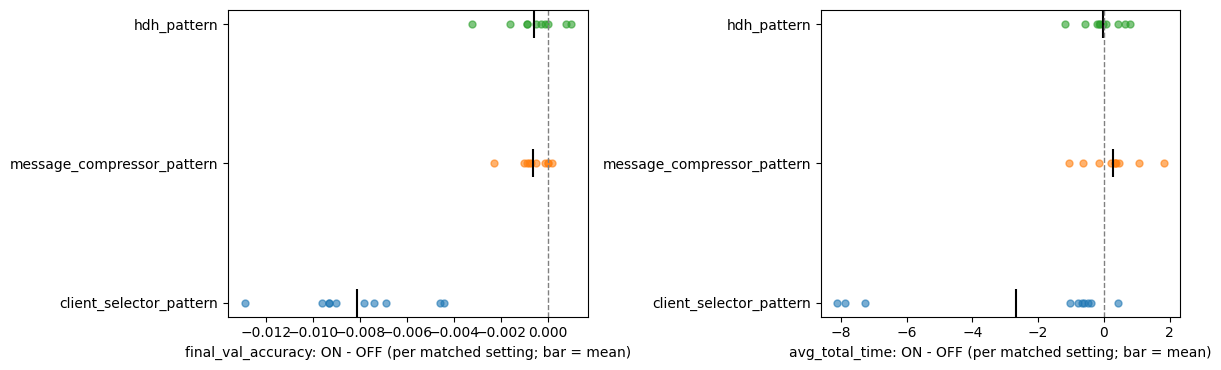

In [18]:
# One point per matched setting: the within-setting difference (pattern ON - OFF)
if contrast_settings:
    fig, axes = plt.subplots(1, len(contrast_objectives), figsize=(6 * len(contrast_objectives), 0.6 * len(contrast_settings) + 2),
                             squeeze=False)
    for ax, objective in zip(axes[0], contrast_objectives):
        for y, (decision, settings) in enumerate(contrast_settings.items()):
            diffs = settings[f"{objective} diff"]
            ax.scatter(diffs, [y] * len(diffs), alpha=0.6, s=25)
            ax.scatter([diffs.mean()], [y], marker='|', s=400, color='black')
        ax.axvline(0, color='grey', linestyle='--', linewidth=1)
        ax.set_yticks(range(len(contrast_settings)), list(contrast_settings))
        ax.set_xlabel(f"{objective}: ON - OFF (per matched seed-setting; bar = mean)")
    plt.tight_layout()
    plt.show()

In [19]:
# Contrast by composition: compare the same decision across the other-pattern combinations
for decision in varying_decisions:
    _, summary = session.get_decision_contrasts(decision, MATCH_ON, others='all', objectives=contrast_objectives)
    if summary.empty or len(summary) < 2:
        continue
    print(f"\n=== {decision}: ON - OFF per combination of the other patterns ===")
    display(summary[['settings'] + [f"{o} diff {k}" for o in contrast_objectives for k in ('mean', '>0')]].round(3))


=== client_selector_pattern: ON - OFF per combination of the other patterns ===


,settings,final_val_accuracy diff mean,final_val_accuracy diff >0,avg_total_time diff mean,avg_total_time diff >0
context,,,,,
"message_compressor_pattern=OFF, hdh_pattern=OFF",10,-0.008,0.0,-2.676,0.1
"message_compressor_pattern=OFF, hdh_pattern=ON",10,-0.008,0.0,-2.719,0.2
"message_compressor_pattern=ON, hdh_pattern=OFF",10,-0.007,0.0,-2.549,0.4
"message_compressor_pattern=ON, hdh_pattern=ON",10,-0.008,0.0,-2.344,0.2



=== message_compressor_pattern: ON - OFF per combination of the other patterns ===


,settings,final_val_accuracy diff mean,final_val_accuracy diff >0,avg_total_time diff mean,avg_total_time diff >0
context,,,,,
"client_selector_pattern=OFF, hdh_pattern=OFF",10,-0.001,0.1,0.282,0.7
"client_selector_pattern=OFF, hdh_pattern=ON",10,0.001,0.7,0.178,0.5
"client_selector_pattern=ON, hdh_pattern=OFF",10,0.000,0.4,0.410,0.7
"client_selector_pattern=ON, hdh_pattern=ON",10,-0.000,0.5,0.553,0.8



=== hdh_pattern: ON - OFF per combination of the other patterns ===


,settings,final_val_accuracy diff mean,final_val_accuracy diff >0,avg_total_time diff mean,avg_total_time diff >0
context,,,,,
"client_selector_pattern=OFF, message_compressor_pattern=OFF",10,-0.001,0.2,-0.034,0.4
"client_selector_pattern=OFF, message_compressor_pattern=ON",10,0.001,0.5,-0.139,0.5
"client_selector_pattern=ON, message_compressor_pattern=OFF",10,0.000,0.4,-0.077,0.3
"client_selector_pattern=ON, message_compressor_pattern=ON",10,-0.000,0.7,0.066,0.5


### How to read the matched-pair chart and table

The chart puts each pattern’s ON-minus-OFF differences on a horizontal axis, with one row per pattern decision and one dot per matched setting. A matched setting is the same task, client count, environment shares, and `partition_seed` in both arms. The overview has many task/client/environment/seed matches; a fixed stress notebook has ten seed matches for each comparison. This is a comparison of two separate runs using the same recorded data partition, not a plot of the same run twice.

- The dashed vertical line at **0** means equal outcomes for the two arms in that matched setting. Dots to either side show the direction and size of the difference in the objective’s own units. Points can overlap, so a dense patch may contain several matched settings.
- For **accuracy**, a dot to the right means ON had higher accuracy; to the left means ON had lower accuracy. For **round time**, a dot to the left means ON was faster; to the right means ON took longer. The favorable side therefore depends on which objective is being viewed.
- The black vertical marker is the **mean difference** across the displayed matched settings. It is not a confidence interval or a guarantee for a new run. A mean near zero can hide positive and negative dots; a wide dot spread means the observed result varied across matched settings/seeds.
- Read the `settings`, `runs ref`, and `runs treat` counts with the plot. Settings without both arms are omitted. Because `partition_seed` is included, each arm contributes one run per matched seed-setting here. Host, scheduling, and other unrecorded conditions are not matched.

The summary table reports the mean, minimum, maximum, and share of positive differences. A positive difference favors ON for accuracy but favors OFF for time. The final composition table repeats the contrast with each combination of the other patterns held fixed; compare its means and support counts to see whether a pattern’s observed behavior changes with the surrounding configuration. A sign change is a reason to inspect that context, not proof of an interaction or a causal effect.

## 6. Robustness Analysis (Quantifying Stability)

Contingency (Section 5) describes *where* the runs of each policy group land. Robustness takes one target tradeoff at a time and asks how reliably each group reaches it, and how badly it misses when it does not:

- **STARR (success rate)**: the share of a group's runs that fall in the target region. Higher is better.
- **REGRET (risk)**: for each run, the distance from its objective values to the bounds of the target region, with each objective divided by its standard deviation (0 for runs inside the region). A group's regret is the mean over its runs. Lower is better.

The robustness matrix and heatmap use the test runs, the runs on which the boxes are evaluated later (Section 11); the ranking below uses all runs.

In [20]:
metric = 'starr' #'starr' 'regret'

In [21]:
base_robustness_matrix = session.get_robustness_report(metric=metric, subset='test') 
base_robustness_matrix # Test

,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
policy,,,,,,,,,
"OFF,OFF,OFF",0.0,0.0,0.0,0.000000,0.0,1.000000,0.0,0.0,0.0
"OFF,OFF,ON",0.0,0.0,0.0,0.000000,0.0,1.000000,0.0,0.0,0.0
"OFF,ON,OFF",0.0,0.0,0.0,0.000000,0.0,1.000000,0.0,0.0,0.0
"OFF,ON,ON",0.0,0.0,0.0,0.000000,0.0,1.000000,0.0,0.0,0.0
"ON,OFF,OFF",0.0,0.0,0.0,0.000000,0.0,1.000000,0.0,0.0,0.0
"ON,OFF,ON",0.0,0.0,0.0,0.500000,0.0,0.500000,0.0,0.0,0.0
"ON,ON,OFF",0.0,0.0,0.0,0.666667,0.0,0.333333,0.0,0.0,0.0
"ON,ON,ON",0.0,0.0,0.0,0.000000,0.0,1.000000,0.0,0.0,0.0


Robustness Ranking for Tradeoff: S-S
  1. OFF,OFF,OFF: 0% success
  2. OFF,OFF,ON: 0% success
  3. OFF,ON,OFF: 0% success
  Top Policy -> OFF,OFF,OFF - Starr: 0.0000 - Regret: 10.0362
Robustness Ranking for Tradeoff: S-M
  1. OFF,OFF,OFF: 0% success
  2. OFF,OFF,ON: 0% success
  3. OFF,ON,OFF: 0% success
  Top Policy -> OFF,OFF,OFF - Starr: 0.0000 - Regret: 9.8816
Robustness Ranking for Tradeoff: S-L
  1. OFF,OFF,OFF: 0% success
  2. OFF,OFF,ON: 0% success
  3. OFF,ON,OFF: 0% success
  Top Policy -> OFF,OFF,OFF - Starr: 0.0000 - Regret: 9.8620
Robustness Ranking for Tradeoff: M-S
  1. ON,OFF,OFF: 30% success
  2. ON,OFF,ON: 30% success
  3. ON,ON,OFF: 30% success
  Top Policy -> ON,OFF,OFF - Starr: 0.3000 - Regret: 1.1663
Robustness Ranking for Tradeoff: M-M
  1. OFF,OFF,OFF: 0% success
  2. OFF,OFF,ON: 0% success
  3. OFF,ON,OFF: 0% success
  Top Policy -> OFF,OFF,OFF - Starr: 0.0000 - Regret: 0.6135
Robustness Ranking for Tradeoff: M-L
  1. OFF,OFF,OFF: 100% success
  2. OFF,OFF,ON: 

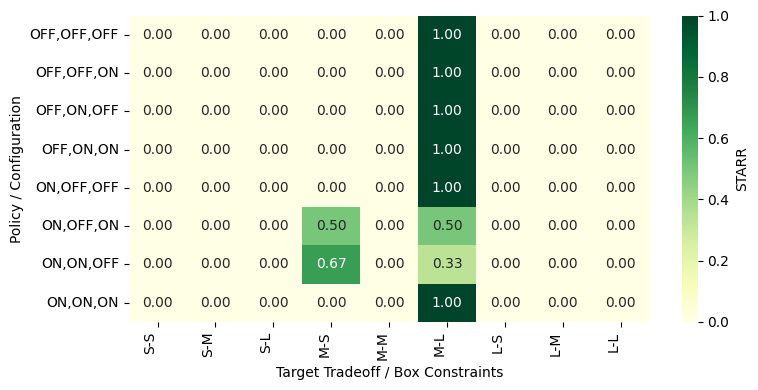

In [22]:
for tradeoff in session.get_tradeoffs():
    print(f"Robustness Ranking for Tradeoff: {tradeoff.name}")
    ranking = session.get_policy_robustness_ranking(tradeoff.name, metric='starr')
    for i, (pol, val) in enumerate(ranking[:3]):
        print(f"  {i+1}. {pol}: {val:.0%} success")
    
    if ranking:
        top_pol = ranking[0][0]
        starr = session.compute_robustness(top_pol, tradeoff.name, metric='starr')
        regret = session.compute_robustness(top_pol, tradeoff.name, metric='regret')
        print(f"  Top Policy -> {top_pol} - Starr: {starr.get('value', 0.0):.4f} - Regret: {regret.get('value', 0.0):.4f}")

if metric == 'starr':
    print("Overall Robustness Heatmap (STARR):")
    session.show_robustness_heatmap(matrix=base_robustness_matrix, metric='starr', figsize=(8,4))
    plt.show()

if metric == 'regret':
    print("Overall Robustness Heatmap (REGRET):")
    session.show_robustness_heatmap(matrix=base_robustness_matrix, metric='regret', figsize=(8,4), title=metric)
    plt.show()

### How robustness relates to contingency

- **STARR is a contingency share.** For a group *g* and a region *T*, STARR(*g*, *T*) is the share of *g*'s runs in *T*: the cell (*g*, *T*) of the contingency table with `normalization_mode='population'` (the default). On the same runs the two tables hold the same numbers; here they differ only because Section 5 uses all runs and the robustness matrix the test runs.
- **The question changes.** Contingency reads a *row*: how one group spreads over all regions. Robustness reads a *column*: for one target region, which group reaches it most reliably (the ranking). STARR is also the baseline that Section 11 compares with the success rate inside the boxes.
- **REGRET adds what contingency cannot show: how far the misses are.** Groups with the same STARR can be very different choices.

Example (illustrative values), target `L-S` (high accuracy, fast):

| Group | Runs in `L-S` | Where its other runs are | STARR | REGRET |
|:---|:---|:---|---:|:---|
| A | 5 of 10 | `M-S`, just below the accuracy edge | 0.50 | low |
| B | 5 of 10 | `S-L`, far below in accuracy and much slower | 0.50 | high |
| C | 9 of 10 | one run in `S-L` | 0.90 | medium: one large miss averaged over 10 runs |

A and B have the same contingency share and STARR, but A nearly meets the target when it misses: it is the more robust choice. C shows that mean regret mixes how often and how far a group misses, so read it together with STARR.

- **Units.** Regret is in standard deviations of each objective over the loaded runs: comparable across groups and regions of one notebook, not across notebooks.

## 7. Pattern Stress

**Pattern stress** measures how much patterning a run carries (`pattern_stress.py`):

- **`Pattern Instances`** (S_inst), the **primary measure**: how many pattern instances are deployed, summed over the patterns. The same pattern type can have several instances, so S_inst captures the size of the deployment; it depends on the configuration, on the client environment and on the other decisions (the client selector removes clients, and their compressor and HDH instances with them). It is declared as an uncertainty, so boxes on it read as conditional prescriptions.
- **`Pattern Types Active`** (S_types, 0-3), a secondary measure: how many of the three pattern decisions are ON. It is exact (read from the configuration) and set by the architect, so it is declared as a lever.

How the instances are counted:

| Pattern | Count | Source |
|:---|:---|:---|
| client selector | 1 when ON | assumption A1 (not recorded) |
| message compressor | 1 per participating client | assumption A2 (not recorded) |
| HDH | participating clients that did HDH work (`HDH Time > 0`) | **measured** from the per-round data in `detailed/` when available (the load message says so); otherwise assumption A3, one per participating non-IID client |

The measured HDH count matters for the image task, where HDH almost never does any work, so the A3 count would overstate it. The assumptions, the evidence and the open questions are in `compact/README.md`.

Stress levels are **mixtures of configurations**: a stress-level share is a weighted average of the configurations at that level, so read it next to the per-configuration table. Compare levels under the same conditions: one client count and one task, and `ENVIRONMENT = 'common'`, because the campaign did not run every configuration in every environment.

This section needs a spec that declares the stress parameters (`./compact/FLsystem_compact_all.json`); with other specs it is skipped. Only the measures that vary in the loaded runs are analyzed:

| Notebook | `Pattern Types Active` | `Pattern Instances` | What Section 7 shows |
|:---|:---|:---|:---|
| overview, stress notebooks | varies (0-3) | varies | everything: levels, instances, boxes |
| one pattern alone | constant (1) | varies with the environment | how the size of that pattern's deployment relates to the objectives. These notebooks mix client counts and tasks, so the count partly stands for them: compressor instances equal the participating clients, and measured HDH instances are 0 in image runs |
| baseline | constant (0) | constant (0) | nothing to compare: the tables confirm that no pattern is deployed |

In [23]:
STRESS_TYPES, STRESS_INSTANCES = 'Pattern Types Active', 'Pattern Instances'
has_stress = all(c in session.experiments_df.columns for c in (STRESS_TYPES, STRESS_INSTANCES))
objectives = list(TRADEOFF_LABELS)

if not has_stress:
    print("This spec does not declare the pattern-stress parameters "
          "(use './compact/FLsystem_compact_all.json'); Section 7 is skipped.")
    varying_stress = []
else:
    # Only stress measures that vary in these runs can be compared: in a single-configuration
    # slice S_types is constant, and in the baseline both measures are 0.
    varying_stress = [c for c in (STRESS_TYPES, STRESS_INSTANCES) if session.experiments_df[c].nunique() > 1]
    for c in (STRESS_TYPES, STRESS_INSTANCES):
        values = sorted(session.experiments_df[c].unique())
        print(f"{c}: {'varies' if c in varying_stress else 'constant'} in these runs, values {values}")

    config_col = session.sys_def.dataspace.configuration_identification.column
    stress_view = session.raw_df.assign(tradeoff=session.discrete_df.astype(str).agg('-'.join, axis=1))
    by_level = stress_view.groupby(STRESS_TYPES).agg(
        runs=(config_col, 'size'), configurations=(config_col, 'nunique'),
        instances_min=(STRESS_INSTANCES, 'min'), instances_max=(STRESS_INSTANCES, 'max'),
        **{f"{o} (mean)": (o, 'mean') for o in objectives},
    )
    by_config = stress_view.groupby([STRESS_TYPES, config_col]).agg(
        runs=(config_col, 'size'), instances=(STRESS_INSTANCES, 'mean'),
        **{f"{o} (mean)": (o, 'mean') for o in objectives},
    )
    print("Per stress level (S_types):")
    display(by_level.round(3))
    print("Per configuration:")
    display(by_config.round(3))

Pattern Types Active: varies in these runs, values [0, 1, 2, 3]
Pattern Instances: varies in these runs, values [0, 1, 2, 4, 5]
Per stress level (S_types):


,runs,configurations,instances_min,instances_max,final_val_accuracy (mean),avg_total_time (mean)
Pattern Types Active,,,,,,
0,10,1,0,0,0.913,12.369
1,30,3,1,4,0.910,11.560
2,30,3,1,5,0.907,10.744
3,10,1,4,5,0.905,10.170


Per configuration:


runs  instances  final_val_accuracy (mean)  \
Pattern Types Active config_id                                                 
0                    OFF,OFF,OFF    10        0.0                      0.913   
1                    OFF,OFF,ON     10        1.0                      0.912   
                     OFF,ON,OFF     10        4.0                      0.912   
                     ON,OFF,OFF     10        1.0                      0.905   
2                    OFF,ON,ON      10        5.0                      0.913   
                     ON,OFF,ON      10        1.9                      0.905   
                     ON,ON,OFF      10        4.0                      0.905   
3                    ON,ON,ON       10        4.9                      0.905   

                                  avg_total_time (mean)  
Pattern Types Active config_id                           
0                    OFF,OFF,OFF                 12.369  
1                    OFF,OFF,ON                  12.335  
                     OFF,ON,OFF                  12.652  
                     ON,OFF,OFF                   9.694  
2                    OFF,ON,ON                   12.513  
                     ON,OFF,ON                    9.616  
                     ON,ON,OFF                   10.103  
3                    ON,ON,ON                    10.170

,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
policy,,,,,,,,,
Pattern Instances=0,0.0,0.0,0.0,0.00,0.0,1.00,0.0,0.0,0.0
Pattern Instances=1,0.0,0.0,0.0,0.14,0.0,0.86,0.0,0.0,0.0
Pattern Instances=2,0.0,0.0,0.0,0.33,0.0,0.67,0.0,0.0,0.0
Pattern Instances=4,0.0,0.0,0.0,0.14,0.0,0.86,0.0,0.0,0.0
Pattern Instances=5,0.0,0.0,0.0,0.16,0.0,0.84,0.0,0.0,0.0


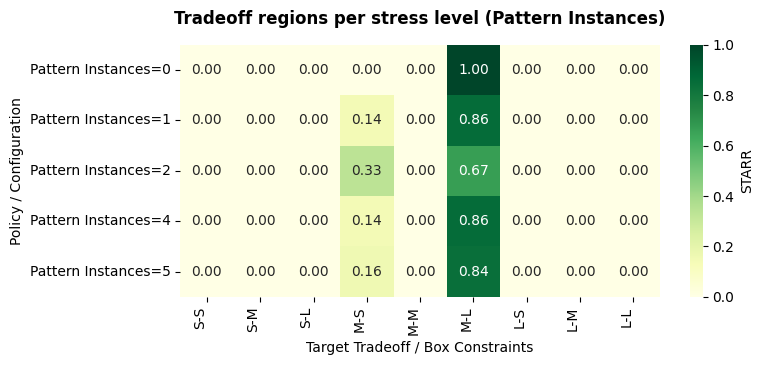

,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
policy,,,,,,,,,
Pattern Types Active=0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
Pattern Types Active=1,0.0,0.0,0.0,0.1,0.0,0.9,0.0,0.0,0.0
Pattern Types Active=2,0.0,0.0,0.0,0.2,0.0,0.8,0.0,0.0,0.0
Pattern Types Active=3,0.0,0.0,0.0,0.3,0.0,0.7,0.0,0.0,0.0


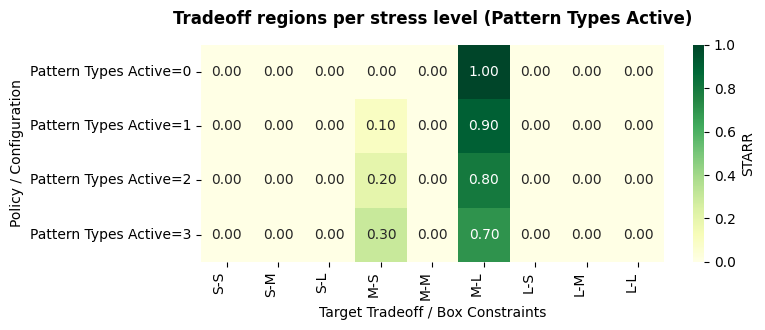

In [24]:
# Share of each stress level's runs in every tradeoff region (STARR, all runs): by the number
# of pattern instances (primary measure), then by the number of pattern types.
# Grouping by a column: rows are '<column>=<level>' (docs/robustness_policy_grouping.md).
for stress_measure in (STRESS_INSTANCES, STRESS_TYPES):
    if stress_measure in varying_stress:
        stress_matrix = session.get_robustness_report(metric='starr', subset='all', by=stress_measure)
        display(stress_matrix.round(2))
        session.show_robustness_heatmap(matrix=stress_matrix, metric='starr',
                                        figsize=(8, 0.35 * len(stress_matrix) + 2),
                                        title=f"Tradeoff regions per stress level ({stress_measure})")
        plt.show()
    elif has_stress:
        print(f"{stress_measure} is constant in these runs: no stress levels to compare.")

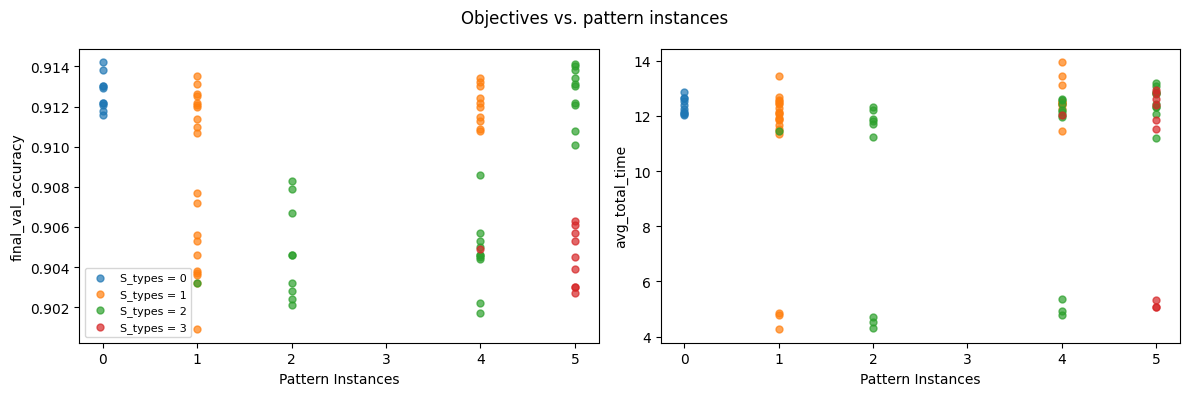

In [25]:
# Objectives against the number of pattern instances (S_inst), colored by S_types
if STRESS_INSTANCES in varying_stress:
    fig, axes = plt.subplots(1, len(objectives), figsize=(6 * len(objectives), 4), squeeze=False)
    for ax, objective in zip(axes[0], objectives):
        for level, group in stress_view.groupby(STRESS_TYPES):
            ax.scatter(group[STRESS_INSTANCES], group[objective], s=25, alpha=0.7, label=f"S_types = {level}")
        ax.set_xlabel(STRESS_INSTANCES)
        ax.set_ylabel(objective)
    axes[0][0].legend(fontsize=8)
    fig.suptitle("Objectives vs. pattern instances")
    plt.tight_layout()
    plt.show()
elif has_stress:
    print(f"{STRESS_INSTANCES} is constant in these runs: nothing to plot.")

In [26]:
# Which amount of patterning leads to each tradeoff? PRIM over the stress measures that vary
# (plus the environment factors that vary in this slice)
if varying_stress:
    environment = [c for c in fl_slices.ENVIRONMENT_COLUMNS
                   if c in session.experiments_df.columns and session.experiments_df[c].nunique() > 1]
    stress_parameters = varying_stress + environment
    print("Parameters:", stress_parameters)
    stress_boxes = []
    for tradeoff in session.get_tradeoffs(non_empty=True):
        with contextlib.redirect_stdout(io.StringIO()):
            boxes = [b for b in session.discover_scenarios(
                tradeoff.name, method='prim', threshold=0.8, parameters=stress_parameters) if not b.is_empty()]
        if boxes:
            box = boxes[0]
            stress_boxes.append(box)
            print(f"{tradeoff.name}: {box.describe_limits()}  "
                  f"(density {box.metrics.get('density', 0):.2f}, coverage {box.metrics.get('coverage', 0):.2f}, "
                  f"lift {box.metrics.get('lift', 0):.2f})")
        else:
            print(f"{tradeoff.name}: no box")
elif has_stress:
    print("No stress measure varies in these runs (e.g. the baseline): no stress boxes to search.")

Parameters: ['Pattern Types Active', 'Pattern Instances']
M-S: no box
M-L: {'Pattern Types Active': '[0.00, 0.00]'}  (density 1.00, coverage 0.15, lift 0.14)


/Users/adiazpace/opt/anaconda3/envs/perfmodels/lib/python3.11/site-packages/prim/prim_box.py:415: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.peeling_trajectory = pd.concat([self.peeling_trajectory, pd.DataFrame([stats])],
/Users/adiazpace/opt/anaconda3/envs/perfmodels/lib/python3.11/site-packages/prim/prim_box.py:415: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.peeling_trajectory = pd.concat([self.peeling_trajectory, pd.DataFrame([stats])],
/Users/adiazpace/opt/anaconda3/envs/perf

### How to read the pattern-instance charts and tables

In **Objectives vs. pattern instances**, each dot is one experiment run. The horizontal position is its estimated total number of deployed pattern instances (`Pattern Instances`); the vertical position is one objective. The two panels show final validation accuracy (higher is better) and average total round time (lower is better). Dot color gives the number of active pattern types: 0, 1, 2, or 3. Dots at the same instance count can overlap, so the visible number of marks is not necessarily the number of runs.

Read the chart as a map of observed outcomes: within one color, compare runs with different instance counts; across colors, compare the different pattern-type groups. If points move toward lower accuracy or longer time as instance count changes, that is an association in these runs, not a prediction that adding an instance will cause that change. Same-color dots may still use different patterns, and both instance count and outcomes can vary with task, client count, environment, and configuration. The overview mixes those conditions; the fixed stress notebooks hold task/client count and the common environment point constant, so they are a better place to inspect a local design comparison.

`Pattern Instances` is a deployment-size estimate, not a direct architecture knob: the client selector changes how many clients participate, and compressor/HDH instance counts depend on participating clients. Some counts are inferred using assumptions A1–A2; HDH uses per-round activity data when available and a fallback rule otherwise. Confirm the count semantics before treating the horizontal axis as measured work.

- The **per-level table** gives the run count, number of configurations, instance range, and mean objectives for each number of active pattern types. Level 0 is baseline alone; levels 1 and 2 combine several configurations. Use the **per-configuration table** to see whether a group mean is driven by one alternative.
- **STARR by level** shows the share of runs in each accuracy/time region at each instance/type level. Check the run counts: rare instance levels can produce unstable shares. The stress notebooks use one task, client count, and common environment; overview-level differences can also reflect changing workload and environment mix.
- The PRIM boxes below identify regions of the observed design space. A bound on active pattern types refers to a configuration choice; a bound on estimated instances or environmental conditions describes when a tradeoff was observed. Use box support, density, and coverage before applying it to a design. These boxes and charts describe where outcomes occurred; they do not establish causal effects.

## 8. Feature Importance & Key-Parameter Selection

The notebook fits a random-forest regressor to each objective's training rows. `include_constraints=True` includes the optional pattern parameters alongside levers and uncertainties. Smart correlation selection first removes redundant encoded features; the score table then restores those removed rows with zero.

Read the heatmap as **relative predictive credit within this fitted model and slice**. The scores are normalized shares of training impurity reduction. They are not fractions of outcome variance explained, percentage changes in accuracy/time, sensitivity slopes, or causal effects, and they give no direction of improvement. Use matched differences and outcome distributions to establish direction.

- **Three meanings of zero:** a feature can be constant in this slice, removed as a correlated duplicate, or retained but unused by the forest. A zero does not establish that the associated decision or uncertainty is irrelevant outside this model/scope.
- **Correlated representatives:** a label such as `Dataset` may stand for a task/model group, and an optional pattern parameter may stand for ON/OFF presence. The representative can change with the objective and the slice; correlation groups can also cross pattern/environment dimensions. A fixed batch size with missing values when OFF measures presence, not batch-size tuning.
- **Scope:** fixing task, client count, or environment removes that variation and redistributes the normalized scores. A higher pattern score in a restricted notebook does not imply a larger physical effect than in the overview.
- **Discovery gate:** equal objective weights order the ranking, but a parameter is selected when its score is **greater than 0.03 in either objective**. This is not a cutoff on the weighted average. A pruned or below-threshold parameter cannot appear directly in the inferred boxes; absence from a rule is therefore not evidence of no association.
- **Consistency and prediction:** a repeatable ranking under model seeds does not establish accurate prediction on unseen runs. The separate [feature-importance audit](../docs/fl_feature_importance_audit.md) checks all 14 notebooks, held-out predictions, correlated proxies, measurement availability, and ranking changes. Those added diagnostics are separate from this heatmap's saved training scores.

Use importance to identify dimensions to inspect. For a design decision, combine it with the observed outcome differences and the supported before/inside-box robustness comparison.

In [27]:
scores_df = session.compute_feature_scores(
    use_smart_correlation=True,
    include_constraints=True,
    subset='train'
)
scores_df

Scoring features for outcome: final_val_accuracy (on subset: train)
Original features (numerically encoded): ['N Rounds', 'Total Clients', 'Model', 'Dataset', 'Optimizer', 'Learning Rate', 'Batch Size', 'Epochs', 'Client Selector Strategy', 'Client Selector Criteria', 'Client Selector Value', 'Message Compressor Alg', 'HDH Batch Size', 'HDH Beta 1', 'HDH Beta 2', 'HDH Discriminator', 'HDH Epochs', 'HDH Generator', 'HDH Learning Rate', 'HDH Latent Dim', 'HDH Optimizer', 'CPU Mean', 'RAM Mean', 'Alpha Dirichlet Mean', 'JSD Mean', 'Data Distribution Diversity', 'Data Persistence Diversity', 'Pattern Types Active', 'Pattern Instances', 'Client Selector Instances', 'Message Compressor Instances', 'HDH Instances', 'low_spec_percentage', 'non_iid_percentage', 'delay_percentage']


Features selected: ['N Rounds', 'Total Clients', 'Model', 'Dataset', 'Optimizer', 'Learning Rate', 'Batch Size', 'Epochs', 'Client Selector Criteria', 'CPU Mean', 'RAM Mean', 'Alpha Dirichlet Mean', 'Data Distribution Diversity', 'Data Persistence Diversity', 'Pattern Types Active', 'Message Compressor Instances', 'HDH Instances', 'low_spec_percentage', 'non_iid_percentage', 'delay_percentage']
Scoring features for outcome: avg_total_time (on subset: train)
Original features (numerically encoded): ['N Rounds', 'Total Clients', 'Model', 'Dataset', 'Optimizer', 'Learning Rate', 'Batch Size', 'Epochs', 'Client Selector Strategy', 'Client Selector Criteria', 'Client Selector Value', 'Message Compressor Alg', 'HDH Batch Size', 'HDH Beta 1', 'HDH Beta 2', 'HDH Discriminator', 'HDH Epochs', 'HDH Generator', 'HDH Learning Rate', 'HDH Latent Dim', 'HDH Optimizer', 'CPU Mean', 'RAM Mean', 'Alpha Dirichlet Mean', 'JSD Mean', 'Data Distribution Diversity', 'Data Persistence Diversity', 'Pattern Ty

Features selected: ['N Rounds', 'Total Clients', 'Model', 'Dataset', 'Optimizer', 'Learning Rate', 'Batch Size', 'Epochs', 'Client Selector Criteria', 'HDH Batch Size', 'CPU Mean', 'RAM Mean', 'Alpha Dirichlet Mean', 'Data Distribution Diversity', 'Data Persistence Diversity', 'Pattern Types Active', 'Message Compressor Instances', 'low_spec_percentage', 'non_iid_percentage', 'delay_percentage']


,final_val_accuracy,avg_total_time
Alpha Dirichlet Mean,0.000000,0.000000
Batch Size,0.000000,0.000000
CPU Mean,0.000000,0.000000
Client Selector Criteria,0.967238,0.557875
Client Selector Instances,0.000000,0.000000
Client Selector Strategy,0.000000,0.000000
Client Selector Value,0.000000,0.000000
Data Distribution Diversity,0.000000,0.000000
Data Persistence Diversity,0.000000,0.000000
Dataset,0.000000,0.000000


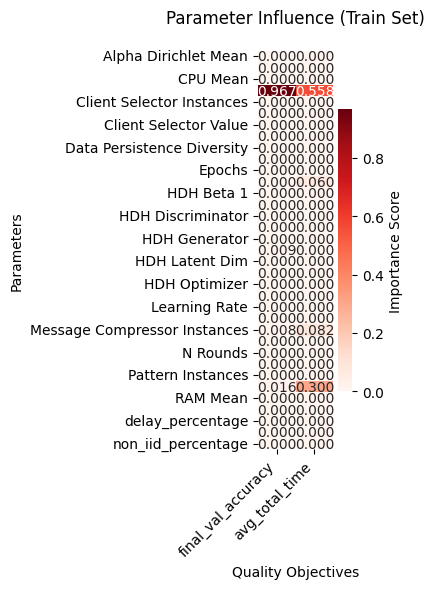

In [28]:
session.show_feature_heatmap(scores_df, title="Parameter Influence (Train Set)", figsize=(4,6))
plt.show()

### Pattern-parameter presence check

All 13 declared pattern parameters must occur as rows in the score table. This catches accidental exclusion through `include_constraints=False`. It verifies that they were offered to scoring; it does not guarantee that they survived correlation pruning, received positive importance, or passed the scenario-discovery gate. Review the selected key-parameter list before interpreting a box as a prescription for a particular pattern.

In [29]:
FL_PATTERN_PARAMETERS = [
    "Client Selector Strategy", "Client Selector Criteria", "Client Selector Value",
    "Message Compressor Alg",
    "HDH Batch Size", "HDH Beta 1", "HDH Beta 2", "HDH Discriminator", "HDH Epochs",
    "HDH Generator", "HDH Learning Rate", "HDH Latent Dim", "HDH Optimizer",
]
assert len(FL_PATTERN_PARAMETERS) == 13

missing = [p for p in FL_PATTERN_PARAMETERS if p not in scores_df.index]
assert not missing, (
    f"compute_feature_scores(include_constraints=True) dropped pattern parameters: {missing}"
)
print(f"All {len(FL_PATTERN_PARAMETERS)} FL pattern parameters are present "
      f"in the feature-importance ranking (R6 verified).")

All 13 FL pattern parameters are present in the feature-importance ranking (R6 verified).


In [30]:
weighted_features = session.get_weighted_feature_ranking(scores_df)
print("Weighted feature ranking:", weighted_features)

# Categorical parameters (e.g. Model) and optional ones (NaN = pattern not selected)
# are encoded numerically by ADEPT, so every ranked parameter can go to discovery.
# A low threshold (0.03) keeps the pattern parameters with a secondary influence next
# to a dominant factor.
key_parameters = session.select_top_k_parameters(
    scores_df, index_order=weighted_features, threshold=0.03, k=None
)
print("Key parameters (for scenario discovery):", key_parameters)

Weighted feature ranking: ['Client Selector Criteria', 'Pattern Types Active', 'Message Compressor Instances', 'HDH Batch Size', 'HDH Instances']
Key parameters (for scenario discovery): ['Client Selector Criteria', 'Pattern Types Active', 'Message Compressor Instances', 'HDH Batch Size']


## 9. Scenario Discovery: PRIM

PRIM searches for parameter boxes associated with non-empty tradeoff regions. `readable_limits()` decodes each condition. Section 10.1 adds a specification-only trace that groups the joint conditions through declared policies and parameter roles; it does not change the learned box or its metrics.

In [31]:
# Scenario discovery uses the key parameters selected in Section 8 (threshold=0.03).
print("Key parameters (for scenario discovery):", key_parameters)

Key parameters (for scenario discovery): ['Client Selector Criteria', 'Pattern Types Active', 'Message Compressor Instances', 'HDH Batch Size']


In [32]:
prim_boxes = []
non_empty_tradeoffs = session.get_tradeoffs(non_empty=True)
for tradeoff in non_empty_tradeoffs:
    print("---" * 10)
    print(f"Discovering scenarios for: {tradeoff.name}")
    boxes = session.discover_scenarios(
        tradeoff.name, method='prim',
        threshold=0.8,
        standardize=True,
        parameters=key_parameters
    )
    non_empty_boxes = [b for b in boxes if not b.is_empty()]
    if non_empty_boxes:
        best_box = non_empty_boxes[0]
        print(f"* Key Rules: {best_box.describe_limits(digits=3)}")
        print(f"* Metrics: {best_box.metrics}")
        prim_boxes.append(best_box)
    else:
        print("--> No scenarios discovered.")

print(f"\n{len(prim_boxes)} non-empty PRIM box(es) discovered across "
      f"{len(non_empty_tradeoffs)} non-empty tradeoffs.")

------------------------------
Discovering scenarios for: M-S
Running PRIM discovery for: M-S ...
Instances satisfying property: False    48
True      8
Name: count, dtype: int64
Total instances: (56, 4)
Running PRIM ... rhodium
5 possible boxes
--> No scenarios discovered.
------------------------------
Discovering scenarios for: M-L
Running PRIM discovery for: M-L ...
Instances satisfying property: True     48
False     8
Name: count, dtype: int64
Total instances: (56, 4)
Running PRIM ... rhodium
5 possible boxes
* Key Rules: {'Client Selector Criteria': '{(not selected)}'}
* Metrics: {'density': 1.0, 'coverage': 0.65, 'population_prevalence': 0.8571428571428571, 'lift': 0.1428571428571429, 'samples_in_box': 13.0, 'targets_in_box': 13.0}

1 non-empty PRIM box(es) discovered across 2 non-empty tradeoffs.


/Users/adiazpace/opt/anaconda3/envs/perfmodels/lib/python3.11/site-packages/prim/prim_box.py:415: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.peeling_trajectory = pd.concat([self.peeling_trajectory, pd.DataFrame([stats])],
/Users/adiazpace/opt/anaconda3/envs/perfmodels/lib/python3.11/site-packages/prim/prim_box.py:415: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.peeling_trajectory = pd.concat([self.peeling_trajectory, pd.DataFrame([stats])],
/Users/adiazpace/opt/anaconda3/envs/perf

In [33]:
# Box rules in original values (see "Reading the rules of a box" below);
# box.readable_limits() gives the exact limits.
boxes_to_keep = []
print("Summary of PRIM boxes:")
for idx, box in enumerate(prim_boxes):
    if not box.is_empty():
        lift = box.metrics.get('lift', None)
        print(f" {idx+1}. For tradeoff {box.target_tradeoff} ({box.target_tradeoff_labels}): lift={lift:.2f}")
        for param, condition in box.describe_limits(digits=3).items():
            print(f"\t{param}: {condition}")
        boxes_to_keep.append(box)
    else:
        solutions = box.metrics.get('targets_in_box', 0)
        print(f" Skipping empty box. For tradeoff {box.target_tradeoff} ({box.target_tradeoff_labels}) {solutions}")
prim_boxes = boxes_to_keep

Summary of PRIM boxes:
 1. For tradeoff M-L (M,L): lift=0.14
	Client Selector Criteria: {(not selected)}


### Reading the PRIM boxes

Each box is a conjunction (**AND**) of conditions. Parameters not listed are unrestricted. The decoded rule and its density, coverage, and lift describe the original box; below, the specification context groups those same conditions through declared components, decisions, policy bindings, and parameter roles.

`(not selected)` is an encoding used for optional values. It identifies OFF only when the system specification declares that applicability relationship. A policy binding points from a policy to a setting (for example, Client Selector ON binds `Client Selector Criteria = CPU`); the explanation does not reverse that link into “CPU requires ON” unless the specification also defines the complementary state. Multiple conditions are read jointly. A lever or uncertainty remains a condition on that parameter unless an explicit policy binding connects it to a decision.

Category intervals are decoded to the category values they cover. Their category ordering is an encoding detail and does not imply similarity. Density, coverage, and support remain properties of the evaluated box, separate from the specification trace.

In [34]:
# Print prim_boxes to a JSON file
# with open('prim_boxes-fl.json', 'w') as f:
#     json_boxes = [box.model_dump() for box in prim_boxes]
#     json.dump(json_boxes, f, indent=4)


## 10. Global Discovery: CART

A decision tree partitions the entire design space into regions, giving a global map of the most likely outcome for any combination of the key parameters.

In [35]:
cart_boxes_all = session.discover_scenarios(method='cart', standardize=True, parameters=key_parameters)
cart_boxes = []
for idx, box in enumerate(cart_boxes_all):
    if not box.is_empty():
        lift = box.metrics.get('lift', None)
        lift_str = f"{lift:.2f}" if lift is not None else "n/a"
        print(f" {idx+1}. For tradeoff {box.target_tradeoff} ({box.target_tradeoff_labels}): lift={lift_str}")
        for param, condition in box.describe_limits(digits=3).items():
            print(f"\t{param}: {condition}")
        cart_boxes.append(box)
    else:
        solutions = box.metrics.get('targets_in_box', 0)
        print(f" Skipping empty box. For tradeoff {box.target_tradeoff} "
              f"({box.target_tradeoff_labels}) {solutions}")

print(f"\n{len(cart_boxes)} non-empty CART box(es) discovered.")

Running CART global discovery for all tradeoff combinations ...
 1. For tradeoff M-L (M,L): lift=0.14
	Client Selector Criteria: {(not selected)}

1 non-empty CART box(es) discovered.


## 10.1 Architectural interpretation of the discovered boxes

Each box is a conjunction. The explanation groups related pattern settings under their policy and shows uncertainty conditions as the operating envelope. The compact text has one line break after the box label. Use `session.explain_box_context(box, output_format="plain")` or `output_format="markdown"`; both formats omit the redundant configuration listing. These are specification consistency descriptions, not separate or causal effects; they do not change box membership or metrics.

In [ ]:
for method_name, discovered_boxes in (("PRIM", prim_boxes), ("CART", cart_boxes)):
    for box_index, box in enumerate(discovered_boxes, start=1):
        if box.is_empty():
            continue
        print(f"{method_name} Box {box_index}: {box.target_tradeoff} ({box.target_tradeoff_labels})\n{session.explain_box_context(box, output_format='plain')['text']}")


### Reading the CART boxes

- **Leaves as boxes.** Each leaf's path is a conjunction of conditions associated with its predicted tradeoff label.
- **Rules.** Read decoded limits as in Section 9. Specification context is shown below for both PRIM and CART boxes.
- **Joint design meaning.** Conditions bound by the same policy are grouped together. Explicit configurations are checked against all relevant declared bindings. Missing applicability or an unbound value is reported as unspecified; it is not guessed from a parameter name or role.
- **Role matters.** A lever or uncertainty condition remains a condition on that parameter unless the JSON declares a policy binding. In particular, a non-IID range is an operating-condition constraint; it does not by itself require HDH ON.
- **CART and PRIM.** Compare their original rules and empirical box metrics separately from this specification-only context. A shared architectural trace does not add evidence about outcomes or causal effects.

In [36]:
# Print cart_boxes to a JSON file
# with open('cart_boxes-fl.json', 'w') as f:
#     json_boxes = [box.model_dump() for box in cart_boxes]
#     json.dump(json_boxes, f, indent=4)


## 11. What-if analysis: robustness after applying box rules

Scenario discovery is useful to a designer because a box can restrict the admissible design/environment space to conditions where the chosen accuracy–time tradeoff is reached more consistently. The tables compare each configuration over its unconstrained test scenarios with the subset satisfying the inferred PRIM or CART rule. Here **baseline robustness** means that configuration's unconstrained rate, including configurations with patterns ON; it does not mean the all-patterns-OFF configuration.

For configuration $d$, target $T$, and box $B$:

- **Before:** $R_0=P(T\mid d)$, the fraction of that configuration's test runs in the target region.
- **Inside the box:** $R_B=P(T\mid d,B)$, the fraction of retained runs in the target. The PRIM/CART matrices below contain these conditional rates, **not the change itself**.
- **Robustness gain:** $R_B-R_0$, reported in percentage points. Compare the baseline and box-constrained matrices for the same configuration and target.
- **Retained scenario fraction:** $P(B\mid d)$ and the retained run count describe how much operating/design freedom the rule leaves. This differs from **target coverage** $P(B\mid T,d)$, the fraction of successful target runs the rule captures. The target-coverage matrices below use the latter meaning.

For the what-if decision, read gain and support together: a rise to 100% based on two retained runs is weaker evidence than the same rate on a larger subset. A displayed zero in a box-constrained matrix can mean that **no scenarios of that configuration are retained**, since the current matrix implementation also fills unsupported cells with zero. It must not automatically be read as an observed failure rate. A `None` column means no box was discovered for that target.

A rule on a pattern decision or lever gives a candidate restriction the designer can implement. A rule on delay, non-IID share, or another uncertainty states an operating envelope: the designer can assess or require that envelope, but selecting a configuration alone does not enforce it. PRIM and CART can offer different gain-versus-retention compromises for the same target.

This what-if evaluation filters held-out observations; it does not rerun the system with changed inputs. Higher STARR demonstrates more consistent **membership in the target tradeoff** across the retained scenarios. It does not by itself demonstrate a lower standard deviation of continuous accuracy or time within that region, or a guaranteed result on a new deployment.

In [37]:
# Rows are policy groups. With several decisions, 'policy' is ambiguous (plain ON/OFF repeats
# across decisions), so the grouping is explicit: by='configuration' (default, one row per
# configuration such as 'OFF,OFF,ON'), by='decision' (rows like 'hdh_pattern:ON') or
# by='<decision>'. base_robustness_matrix must be computed with the same `by`.
# See docs/robustness_policy_grouping.md.
combined_df = session.get_robustness_results(prim_boxes, cart_boxes, baseline=base_robustness_matrix, by='configuration')
# combined_df.to_csv('results-fl.csv', index=False, decimal=',')
combined_df

,method,policy,target,L-L,L-M,L-S,M-L,M-M,M-S,S-L,S-M,S-S
0,test set,"OFF,OFF,OFF",,0.0,0.0,0.0,1.000000,0.0,0.000000,0.0,0.0,0.0
1,test set,"OFF,OFF,ON",,0.0,0.0,0.0,1.000000,0.0,0.000000,0.0,0.0,0.0
2,test set,"OFF,ON,OFF",,0.0,0.0,0.0,1.000000,0.0,0.000000,0.0,0.0,0.0
3,test set,"OFF,ON,ON",,0.0,0.0,0.0,1.000000,0.0,0.000000,0.0,0.0,0.0
4,test set,"ON,OFF,OFF",,0.0,0.0,0.0,1.000000,0.0,0.000000,0.0,0.0,0.0
5,test set,"ON,OFF,ON",,0.0,0.0,0.0,0.500000,0.0,0.500000,0.0,0.0,0.0
6,test set,"ON,ON,OFF",,0.0,0.0,0.0,0.333333,0.0,0.666667,0.0,0.0,0.0
7,test set,"ON,ON,ON",,0.0,0.0,0.0,1.000000,0.0,0.000000,0.0,0.0,0.0
8,prim,"OFF,OFF,OFF",M-L,0.0,0.0,0.0,1.000000,0.0,0.000000,0.0,0.0,0.0
9,prim,"OFF,OFF,ON",M-L,0.0,0.0,0.0,1.000000,0.0,0.000000,0.0,0.0,0.0


In [38]:
prim_box_list = session.align_boxes_to_tradeoffs(prim_boxes) # PRIM

prim_robustness_improvement_matrix = session.get_policy_robustness_improvement_matrix(prim_box_list, metric=metric, subset='test')
prim_robustness_improvement_matrix

,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
"OFF,OFF,OFF",None,None,None,None,None,1.0,None,None,None
"OFF,OFF,ON",None,None,None,None,None,1.0,None,None,None
"OFF,ON,OFF",None,None,None,None,None,1.0,None,None,None
"OFF,ON,ON",None,None,None,None,None,1.0,None,None,None
"ON,OFF,OFF",None,None,None,None,None,0.0,None,None,None
"ON,OFF,ON",None,None,None,None,None,0.0,None,None,None
"ON,ON,OFF",None,None,None,None,None,0.0,None,None,None
"ON,ON,ON",None,None,None,None,None,0.0,None,None,None


In [39]:
session.get_tradeoff_coverage_matrix(prim_boxes, subset='test')

,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
M-L,0.0,0.0,0.0,0.0,0.0,0.65,0.0,0.0,0.0


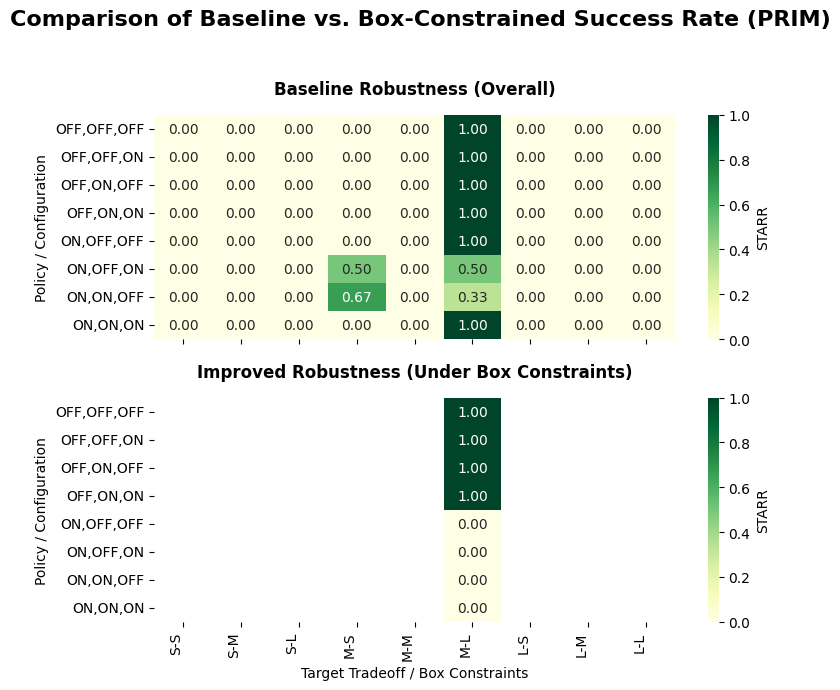

In [40]:
fig = session.show_policy_robustness_comparison_heatmap(
    baseline_matrix=base_robustness_matrix,
    improved_matrix=prim_robustness_improvement_matrix,
    boxes=prim_box_list, 
    metric=metric, 
    figsize=(8,7),
    title="Comparison of Baseline vs. Box-Constrained Success Rate (PRIM)"
)

In [41]:
cart_box_list = session.align_boxes_to_tradeoffs(cart_boxes) # CART

cart_robustness_improvement_matrix = session.get_policy_robustness_improvement_matrix(cart_box_list, metric=metric, subset='test')
cart_robustness_improvement_matrix

,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
"OFF,OFF,OFF",None,None,None,None,None,1.0,None,None,None
"OFF,OFF,ON",None,None,None,None,None,1.0,None,None,None
"OFF,ON,OFF",None,None,None,None,None,1.0,None,None,None
"OFF,ON,ON",None,None,None,None,None,1.0,None,None,None
"ON,OFF,OFF",None,None,None,None,None,0.0,None,None,None
"ON,OFF,ON",None,None,None,None,None,0.0,None,None,None
"ON,ON,OFF",None,None,None,None,None,0.0,None,None,None
"ON,ON,ON",None,None,None,None,None,0.0,None,None,None


In [42]:
session.get_tradeoff_coverage_matrix(cart_boxes, subset='test')

,S-S,S-M,S-L,M-S,M-M,M-L,L-S,L-M,L-L
M-L,0.0,0.0,0.0,0.0,0.0,0.65,0.0,0.0,0.0


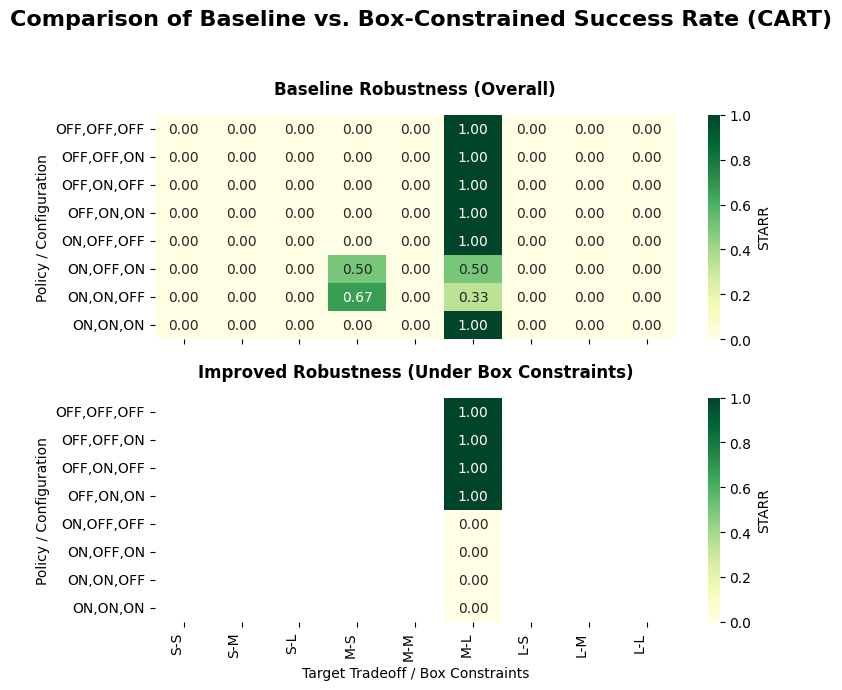

In [43]:
fig = session.show_policy_robustness_comparison_heatmap(
    baseline_matrix=base_robustness_matrix,
    improved_matrix=cart_robustness_improvement_matrix,
    boxes=cart_box_list, 
    metric=metric, 
    figsize=(8,7),
    title="Comparison of Baseline vs. Box-Constrained Success Rate (CART)"
)

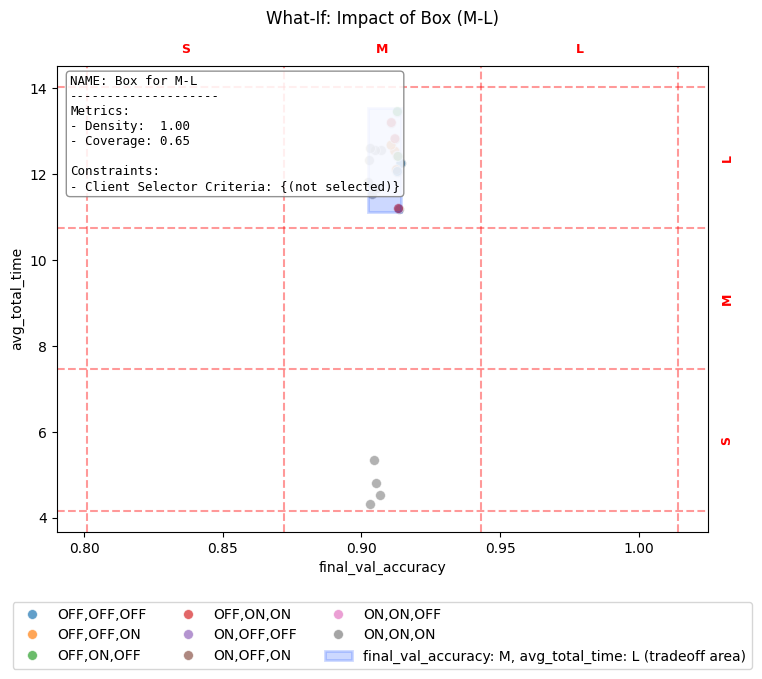

In [44]:
# Visualization of an example box: the first tradeoff that has a CART box
# (cart_box_list is aligned with `tradeoffs`; tradeoffs without a box hold None)
example = next(((box, t) for box, t in zip(cart_box_list, tradeoffs) if box is not None), None)
if example is None:
    print("No CART box to visualize.")
else:
    example_box, example_tradeoff = example
    for x_col, y_col in itertools.combinations(outcome_cols, 2):
        session.show_box_impact_objective_space(
            box=example_box,
            x_metric=x_col, 
            y_metric=y_col,
            tradeoff=session.get_tradeoff(example_tradeoff.name),
            show_box_summary=True,
            subset='test',
            cmap='tab10', 
            alpha=0.7,
            figsize=(8, 7),
            s=50
        )
        plt.show()


## 12. Box Diagnostics and "Not Selected" Hatching

We first visualize the first non-empty discovered box (PRIM or CART). We then look for a box that also covers the "not selected" state of some optional parameter (`box.includes_na`), which the diagnostics plot draws as a hatched N/A region.

A box covers the "not selected" state when it describes runs where a pattern is OFF, e.g. a limit on `Client Selector Criteria` that includes its "not selected" value. The cell below renders the first such box, or reports that none was found.

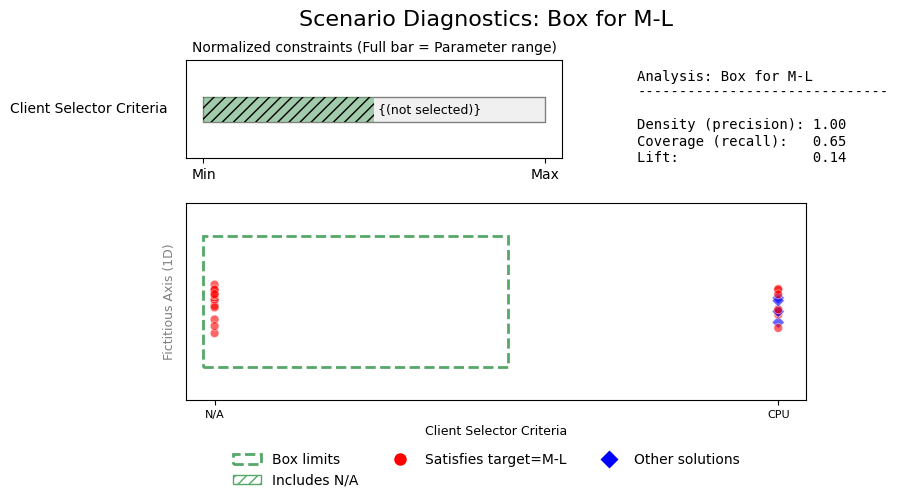

In [45]:
all_boxes = prim_boxes + cart_boxes

if all_boxes:
    first_box = all_boxes[0]
    fig = session.show_box_diagnostics(box=first_box, subset='test', show_policies=False, figsize=(8, 5))
    plt.show()
else:
    print("No non-empty boxes were discovered by PRIM or CART; skipping box diagnostics.")

R10: box for M-L also covers 'Client Selector Criteria' = not selected: {'in': ['(not selected)'], 'includes_na': True}. Rendering N/A-hatching diagnostics:


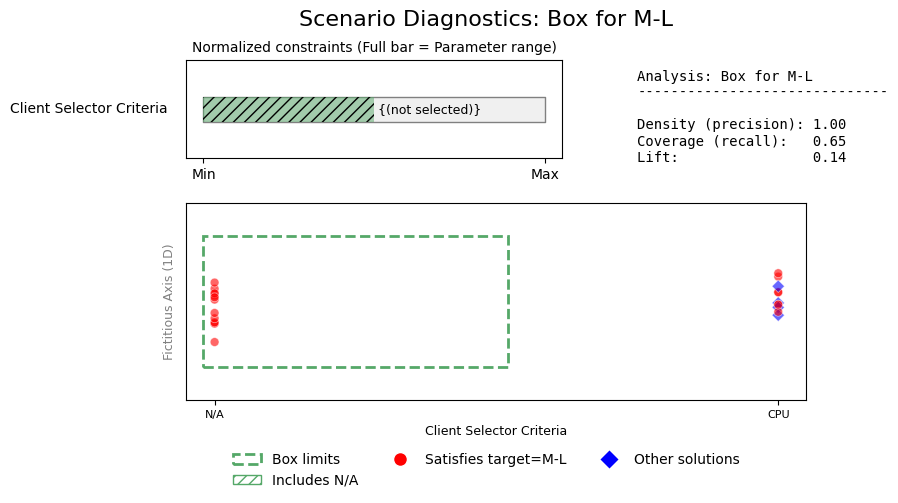

In [46]:
# Boxes record which optional parameters they cover in the "not selected" state
# (box.includes_na); readable_limits() marks those parameters with includes_na.
na_hatching_box = next(
    ((box, param) for box in all_boxes for param, covered in box.includes_na.items() if covered),
    None
)

if na_hatching_box:
    box, param_name = na_hatching_box
    print(f"R10: box for {box.target_tradeoff} also covers '{param_name}' = not selected: "
          f"{box.readable_limits()[param_name]}. Rendering N/A-hatching diagnostics:")
    fig = session.show_box_diagnostics(box=box, subset='test', show_policies=False, figsize=(8, 5))
    plt.show()
else:
    print("R10: no PRIM/CART box discovered in this run covers an optional parameter's "
          "'not selected' state, so there is no N/A region to hatch.")

/var/folders/tx/dmzj44qn2s92dyzxj_nrc82c0000gn/T/ipykernel_41798/390917906.py:3: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


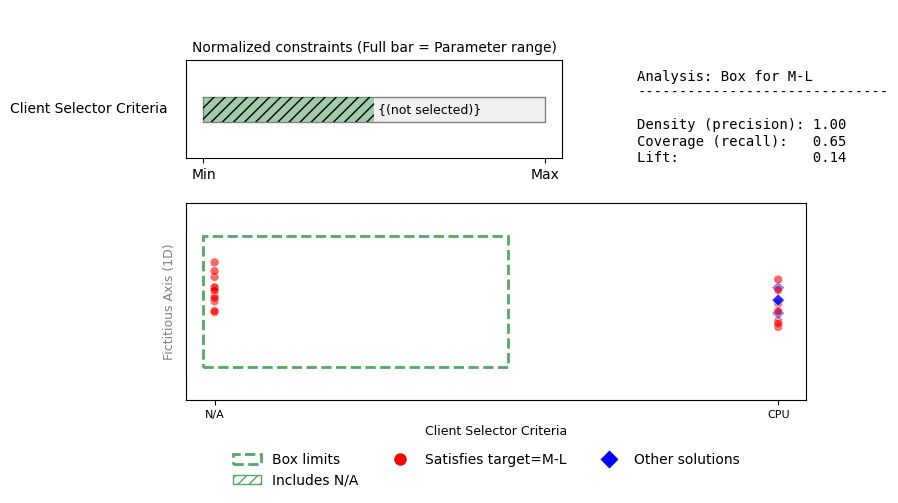

In [47]:
for box in prim_boxes: # Inspect PRIM boxes
    fig = session.show_box_diagnostics(box, subset='test', show_policies=False, figsize=(8,5), title=" ") #, palette='tab10')
    fig.show()

/var/folders/tx/dmzj44qn2s92dyzxj_nrc82c0000gn/T/ipykernel_41798/534013300.py:3: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


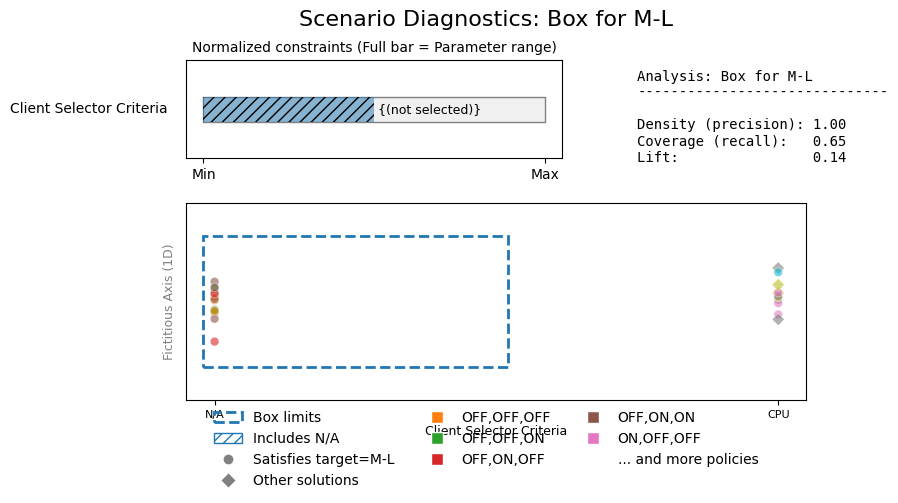

In [48]:
for box in cart_boxes: # Inspect CART boxes
    fig = session.show_box_diagnostics(box, subset='test', show_policies=True, figsize=(8,5)) #, palette='tab10')
    fig.show()

## 13. Performance Metrics

In [49]:
# PRIM
scores = session.get_algorithm_performance_scores(prim_boxes, return_std=True, subset='test')
metrics_df = pd.DataFrame(scores.items(), columns=['metric', 'value'])
df = metrics_df.T
prim_df = pd.DataFrame(df.values[1:], columns=df.iloc[0])
metrics_df

2 tradeoffs to evaluate. 1 1


,metric,value
0,precision,5.000000e-01
1,recall,3.250000e-01
2,f1,3.939394e-01
3,lift,-1.387779e-17
4,complexity,1.000000e+00
5,success_rate,5.000000e-01
6,precision_std,5.000000e-01
7,recall_std,3.250000e-01
8,f1_std,3.939394e-01
9,lift_std,1.666667e-01


In [50]:
# CART
scores = session.get_algorithm_performance_scores(cart_boxes, return_std=True, subset='test')
metrics_df = pd.DataFrame(scores.items(), columns=['metric', 'value'])
df = metrics_df.T
cart_df = pd.DataFrame(df.values[1:], columns=df.iloc[0])
metrics_df


2 tradeoffs to evaluate. 1 1


,metric,value
0,precision,5.000000e-01
1,recall,3.250000e-01
2,f1,3.939394e-01
3,lift,-1.387779e-17
4,complexity,1.000000e+00
5,success_rate,5.000000e-01
6,precision_std,5.000000e-01
7,recall_std,3.250000e-01
8,f1_std,3.939394e-01
9,lift_std,1.666667e-01


In [51]:
all_metrics = pd.concat([prim_df, cart_df], axis=0)
all_metrics.index = ['prim', 'cart']
# all_metrics.to_csv('metrics-fl.csv', decimal=',')
all_metrics

metric,precision,recall,f1,lift,complexity,success_rate,precision_std,recall_std,f1_std,lift_std,complexity_std
prim,0.5,0.325,0.393939,-0.0,1.0,0.5,0.5,0.325,0.393939,0.166667,0.0
cart,0.5,0.325,0.393939,-0.0,1.0,0.5,0.5,0.325,0.393939,0.166667,0.0
